# Cursor-shape analysis

What does the **BCI cursor** do on a single trial, how does that shape change **within a day**,
**across days / learning stages**, and — for the remapping animal — between **intuitive-axis**,
**new-axis** and **washout** control? Finally, can trials be **clustered** by cursor shape, and do
those clusters map onto day, phase or time-within-session?

Reusable tools live in `utilities/cursor_analysis_utils.py` (imported as `ca`), with trial/block
handling from `utilities/neural_analysis_utils.py` (`na`). All analysis flow and plotting stay open in
this notebook. **Correct and incorrect trials are analysed separately throughout.**

This notebook computes and displays; it deliberately does **not** draw conclusions.

---

## Methods, assumptions and analysis choices

### 1. Which cursor signal
The decoder logger holds several correlated but different cursor signals at **one row per imaging
frame (30 Hz)**. `CURSOR_COLUMN` selects among them; the default is **`freqToOutput`**, the commanded
auditory tone in Hz — the closest available proxy for what the animal actually hears.

`r["data_ws"][day]["cursor"]` (the analog WaveSurfer readback) is also selectable as
`"data_ws_cursor"`, but it is *not* the default: it lags `freqToOutput` by ~1 frame (33 ms), is ~5×
more coarsely quantised, and carries measurement noise, all of which are recording artefacts rather
than things the animal perceives.

Both storage formats are handled (`extras/logger_dfs` → a saved DataFrame with an extra leading
`Unnamed: 0` column; `extras/loggers` → a bare array needing an explicit column list), so columns are
always addressed **by name**.

### 2. Representation: log2 (octaves)
`CURSOR_TRANSFORM = "log2"` by default. Pitch is perceived approximately logarithmically, and the task
maps the cursor exponentially onto frequency precisely so that equal cursor steps feel like equal
pitch steps. Working in octaves therefore makes equal *perceptual* changes equal *numerical* changes.
The tone spans ~1000–15108 Hz ≈ **3.9 octaves** and saturates on <0.05 % of frames, so it behaves as a
clean continuous variable. Set `CURSOR_TRANSFORM = None` for raw Hz.

### 3. Missing samples
The logged cursor is ~86–98 % finite. Missing samples are mostly **isolated single frames**
(dropouts), plus long NaN stretches at the **session edges** where the decoder was not running.
Gaps ≤ `MAX_GAP_SEC` (0.5 s) are linearly interpolated; longer gaps stay NaN, and any trial whose
window is more than `MAX_NAN_FRAC` (10 %) NaN is **rejected** and reported.

### 4. The trial window and time-warping
Each trial contributes the window **`PRE_SEC` before trial start → trial → `POST_SEC` after the
trial's effective end**, where *effective end* is the **reward time** for a correct trial and
**start + `MISS_DUR_SEC`** (the timeout) for an incorrect one — the same convention used elsewhere in
this project.

Trials have very different durations (hits: median ~2.4 s; misses: exactly 20 s), so the **trial
portion is time-warped** to `N_TRIAL_BINS` columns by linear resampling, while the **two flanks keep
their real-time sampling** at 30 Hz. This makes trials comparable column-by-column without distorting
the fixed-duration context around them. The window therefore has
`round(PRE_SEC·30) + N_TRIAL_BINS + round(POST_SEC·30)` columns; the setup cell prints the geometry
actually in force, and the flank/trial boundaries are drawn on every window figure.

*Assumption:* linear time-warping treats a fast and a slow trial as the same shape if they differ only
in speed. Real duration is preserved separately as `duration_sec`, and `path_length_raw_per_s`
restores the speed information that warping removes.

*Checked (Section 11):* the flanks are verified not to reach into a neighbouring trial — the fraction
of inter-trial gaps at least as long as `PRE_SEC + POST_SEC` is reported there. Widening the flanks
makes this check stricter, so re-read it after changing `PRE_SEC` / `POST_SEC`.

### 5. Shape metrics
Three families, all defined in `ca.shape_metrics` (units = octaves when `log2` is used):

* **Amplitude / level** — `pre_level`, `peak`, `trough`, `range`, `mean_level`, `end_level`,
  `net_change` (end − pre-trial level), `post_drop` (end − post-flank mean).
* **Excursion / path** — `path_length` (whole window), `path_length_trial`,
  `path_length_raw_per_s` (trial path ÷ real duration, i.e. actual speed),
  `tortuosity` (trial path ÷ |net displacement|; 1 = a straight monotone ramp, large = wandering).
* **Shape**, computed after standardising each trial (time → [0, 1], cursor → z-score) so they are
  invariant to offset and gain — `mean_curvature`, `max_curvature` (planar curvature
  `|y''|/(1+y'²)^{3/2}`), `roughness` (mean |2nd difference|), `monotonicity` (Spearman ρ of cursor vs
  time within the trial; +1 = clean ramp up), `n_peaks`, `time_to_peak` (0 = trial start, 1 = trial end).

*Assumption:* curvature is **not** scale-invariant, so it is only meaningful on the standardised
shape, and its absolute magnitude depends on `N_TRIAL_BINS`. Compare it only like-for-like within this
notebook, never across different binnings.

### 6. Clustering
The warped matrix is optionally row-normalised (`NORMALIZE_MODE`), reduced by **PCA keeping enough PCs
to reach `PCA_VAR_TARGET` (95 %)**, then clustered by **Ward hierarchical clustering**, with **t-SNE**
and **UMAP** used only as 2-D *views* of the same PCA scores (never as the clustering input).

`NORMALIZE_MODE = "none"` is the default: on log2 data this keeps genuine differences in pitch level
and modulation depth, which are behaviourally meaningful. `"zscore"` isolates shape alone,
`"minmax"` keeps shape and relative timing, `"center"` removes only the starting pitch — all are
available and the choice is reported with every clustering result.

*Assumption:* `k` is chosen by a silhouette scan plus the dendrogram, both shown. Silhouette is a
heuristic, not a test — the cluster count is a modelling choice, not a discovered truth.

## 1 · Setup and configuration

In [1]:
%matplotlib inline
import sys, warnings, time
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, mannwhitneyu, kruskal, chi2_contingency
from scipy.cluster.hierarchy import dendrogram

REPO = Path.cwd(); sys.path.insert(0, str(REPO / "utilities"))
import importlib
import neural_analysis_utils as na; importlib.reload(na)
import cursor_analysis_utils as ca; importlib.reload(ca)
import richfile as rfs; na.register_richfile_types(rfs)
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k): return x

# ============================ CONFIG ============================
SR = 30
DATA_ROOT = Path(r"C:\Data\datasets\bmi_packets\bmi_packets")
OUT = REPO / "output" / "cursor_shape"; OUT.mkdir(parents=True, exist_ok=True)
MICE = ["mouse_0403L", "mouse_0322R", "mouse_0403R", "mouse_0916N"]
REMAP_MOUSE = "mouse_0403L"          # the only animal with a remapping phase
CLUSTER_MOUSE = "mouse_0403L"        # which animal the clustering sections use

# --- cursor signal ---
CURSOR_COLUMN = "freqToOutput"       # any of ca.CURSOR_SOURCES
CURSOR_TRANSFORM = "log2"            # "log2" (octaves) or None (raw units)
MAX_GAP_SEC = 0.5                    # interpolate NaN runs up to this long
MAX_NAN_FRAC = 0.10                  # reject a trial if its window is more NaN than this

# --- trial window ---
PRE_SEC, POST_SEC, N_TRIAL_BINS = .25, .5, 40
MISS_DUR_SEC = 20.0                  # incorrect-trial timeout = effective end
SPEC = ca.WindowSpec(pre_sec=PRE_SEC, post_sec=POST_SEC, n_trial_bins=N_TRIAL_BINS, sr=SR)

# --- clustering ---
NORMALIZE_MODE = "none"              # "none" | "zscore" | "minmax" | "center"
PCA_VAR_TARGET = 0.95
K_RANGE = range(2, 11)
N_CLUSTERS = 4                    # None -> pick the silhouette maximum
TSNE_PERPLEXITY, UMAP_NEIGHBORS, UMAP_MIN_DIST = 30.0, 25, 0.1
SEED = 0

USE_CACHE = True
TAG = f"{CURSOR_COLUMN}_{CURSOR_TRANSFORM}_p{PRE_SEC}s{POST_SEC}_b{N_TRIAL_BINS}"
# ---------------------------- figure control ----------------------------
# Every figure is always saved to output/cursor_shape/. FIG_LEVEL only controls which are
# DISPLAYED inline, so the notebook stays readable without losing any result:
#   "summary" -> the headline figures (default)
#   "full"    -> everything, including per-animal repeats and sensitivity panels
FIG_LEVEL = "summary"
_LV = {"summary": 0, "full": 1}

def show(fig, name, level="summary"):
    '''Save a figure, and display it only if its level is within FIG_LEVEL.'''
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    if _LV[level] <= _LV[FIG_LEVEL]:
        plt.show()
    else:
        plt.close(fig); print(f"  [{name}] saved (set FIG_LEVEL='full' to display)")

def per_mouse_level(mouse):
    '''Per-animal repeats are shown for the primary animal only, unless FIG_LEVEL="full".'''
    return "summary" if mouse == CLUSTER_MOUSE else "full"

sns.set_context("notebook")
sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "axes.labelsize": 9,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
                     "figure.constrained_layout.use": False})
OUTCOME_COLORS = {"correct": "tab:blue", "incorrect": "tab:red"}
CURSOR_UNITS = ("cursor (octaves)" if CURSOR_TRANSFORM == "log2" else "cursor (raw units)")
if NORMALIZE_MODE != "none":
    CURSOR_UNITS = CURSOR_UNITS + f" [{NORMALIZE_MODE}-normalised]"
K_SENSITIVITY = [2, 3, 4, 5]     # cluster counts shown side by side in Section 8

# --- fair ACROSS-DAY comparison ---
# On a remapping day the session is (intuitive ~0-11 min) -> rotation -> (new axis) -> (washout),
# so a whole-day average mixes three different control regimes and is not comparable with a
# stable-control day. Every across-day comparison therefore uses only the first
# FIRST_MIN_FOR_DAY_COMPARISON minutes of EVERY day, which on remapping days lies entirely inside
# the pre-rotation intuitive block, and on stable days matches time-on-task.
FIRST_MIN_FOR_DAY_COMPARISON = 10.0
REMAP_DAYS_TO_SHOW = [0, 3, 7]   # individual remapping days plotted separately in Section 6

def comparable_subset(df):
    """First FIRST_MIN_FOR_DAY_COMPARISON minutes of each day -- see the note above."""
    return df[df.t_in_session_min <= FIRST_MIN_FOR_DAY_COMPARISON]
print(f"config loaded | cursor: {CURSOR_COLUMN} ({CURSOR_TRANSFORM}) | tag: {TAG}")
print(f"window geometry: {SPEC.pre_n} pre-columns ({PRE_SEC:g} s @ {SR} Hz) + "
      f"{N_TRIAL_BINS} warped trial columns + {SPEC.post_n} post-columns ({POST_SEC:g} s) "
      f"= {SPEC.n_cols} columns")
print(f"across-day comparisons restricted to the first {FIRST_MIN_FOR_DAY_COMPARISON:g} min of each day")

config loaded | cursor: freqToOutput (log2) | tag: freqToOutput_log2_p0.25s0.5_b40
window geometry: 8 pre-columns (0.25 s @ 30 Hz) + 40 warped trial columns + 15 post-columns (0.5 s) = 63 columns
across-day comparisons restricted to the first 10 min of each day


## 2 · Build the per-trial cursor dataset

One pass over every day of every animal. For each **true BMI trial** we extract the warped window,
compute the shape metrics, and record the labels needed later: outcome, day, phase
(`stable` / `remap`), block (`intuitive_pre` / `new` / `washout` on remapping days, `single`
otherwise), decoder `factor`, position of the trial within its day and within its block, and the
within-day tercile (`early` / `middle` / `late`, equal trial counts).

Rejected trials are counted and reported rather than silently dropped.

In [2]:
def day_blocks(trials):
    '''Label each trial with its block. Remapping days are (factor 2, factor 3, factor 2).'''
    blocks = na.segment_factor_blocks(trials)
    lab = np.array(["single"] * len(trials), dtype=object)
    if len(blocks) == 3:
        names = ["intuitive_pre", "new", "washout"]
        for nm, b in zip(names, blocks):
            lab[b.first_trial:b.last_trial + 1] = nm
        phase = "remap"
    else:
        phase = "stable"
    kblock = np.zeros(len(trials), dtype=float) * np.nan
    for b in blocks:
        kblock[b.first_trial:b.last_trial + 1] = np.arange(b.n_trials)
    return lab, phase, kblock

def build_dataset():
    Ms, metas = [], []
    reject_rows = []
    for mouse in MICE:
        r = na.open_mouse(rfs, DATA_ROOT, mouse)
        days = na.get_day_list(r)
        day0 = r["date_day0"].load()
        day0 = str(np.asarray(day0).ravel()[0]) if not isinstance(day0, str) else day0
        d0i = days.index(day0) if day0 in days else 0
        for di, day in enumerate(tqdm(days, desc=mouse)):
            trials = na.get_true_bmi_trials(na.get_trials_df(r, day))
            if len(trials) == 0:
                continue
            try:
                cursor = ca.load_cursor_signal(r, day, column=CURSOR_COLUMN,
                                               transform=CURSOR_TRANSFORM,
                                               max_gap_sec=MAX_GAP_SEC, sr=SR)
            except Exception as e:
                reject_rows.append(dict(mouse=mouse, day=day, reason=f"load_failed:{type(e).__name__}", n=len(trials)))
                continue
            rew = na.get_active_reward_frames(r, day)
            eff = na.effective_trial_end(trials, reward_frames=rew, miss_dur_sec=MISS_DUR_SEC, sr=SR)
            M, kept, info = ca.extract_trial_windows(cursor, trials.start, eff, SPEC, max_nan_frac=MAX_NAN_FRAC)
            for reason, cnt in info.reject.value_counts().items():
                if reason:
                    reject_rows.append(dict(mouse=mouse, day=day, reason=reason, n=int(cnt)))
            if len(M) == 0:
                continue
            blk, phase, kblock = day_blocks(trials)
            dur = (eff - trials.start)[kept] / SR
            meta = pd.DataFrame(dict(
                mouse=mouse, day=str(day), day_idx=di, day_from0=di - d0i, phase=phase,
                block=blk[kept], factor=trials.factor[kept], k_in_block=kblock[kept],
                trial_in_day=kept, success=trials.success[kept],
                start_frame=trials.start[kept], end_frame=eff[kept], duration_sec=dur,
                t_in_session_min=trials.start[kept] / SR / 60,
            ))
            meta["outcome"] = np.where(meta.success == 1, "correct",
                                np.where(meta.success == 0, "incorrect", "unknown"))
            meta["tercile"] = ca.within_day_tercile(meta.t_in_session_min.to_numpy())
            metrics = ca.shape_metrics_table(M, SPEC, durations=dur.to_numpy() if hasattr(dur, "to_numpy") else dur)
            metas.append(pd.concat([meta.reset_index(drop=True), metrics.reset_index(drop=True)], axis=1))
            Ms.append(M)
    return np.vstack(Ms), pd.concat(metas, ignore_index=True), pd.DataFrame(reject_rows)

m_fp, t_fp, r_fp = OUT / f"M_{TAG}.npy", OUT / f"trials_{TAG}.csv", OUT / f"rejects_{TAG}.csv"
if USE_CACHE and m_fp.exists() and t_fp.exists():
    M_all = np.load(m_fp)
    trials_df = pd.read_csv(t_fp); trials_df["day"] = trials_df["day"].astype(str)
    rejects = pd.read_csv(r_fp) if r_fp.exists() else pd.DataFrame()
else:
    t0 = time.time()
    M_all, trials_df, rejects = build_dataset()
    np.save(m_fp, M_all); trials_df.to_csv(t_fp, index=False); rejects.to_csv(r_fp, index=False)
    print(f"built in {time.time()-t0:.0f}s")

assert len(M_all) == len(trials_df), "matrix and metadata are out of sync"
print(f"trials kept: {len(trials_df)}   window matrix: {M_all.shape}")
display(trials_df.groupby(["mouse", "phase"]).outcome.value_counts().unstack(fill_value=0))
print("\nrejected trials by reason:")
display(rejects.groupby("reason").n.sum().to_frame("n_trials") if len(rejects) else "none")

trials kept: 16036   window matrix: (16036, 63)


outcome             correct  incorrect
mouse       phase                     
mouse_0322R stable     2934       1865
mouse_0403L remap      4773        248
            stable     4362        349
mouse_0403R stable      902        114
mouse_0916N stable      416         73


rejected trials by reason:


,n_trials
reason,
nan_after_fill,10
too_many_nan,34


## 3 · Average cursor shape per day

**Across-day panels use only the first `FIRST_MIN_FOR_DAY_COMPARISON` (10) minutes of each day**,
so that remapping days contribute only their pre-rotation intuitive block and every day represents the
same control regime and the same time-on-task. The grand-mean panel below it deliberately uses *all*
trials, since it is not an across-day comparison.

Mean ± SEM window per day, correct and incorrect separately. The x-axis is the warped window: negative
values are the pre-trial flank (in units of trial duration), **0 = trial start**, **1 = trial end /
reward**, and > 1 is the post-trial flank. Vertical dashed lines mark the trial boundaries.

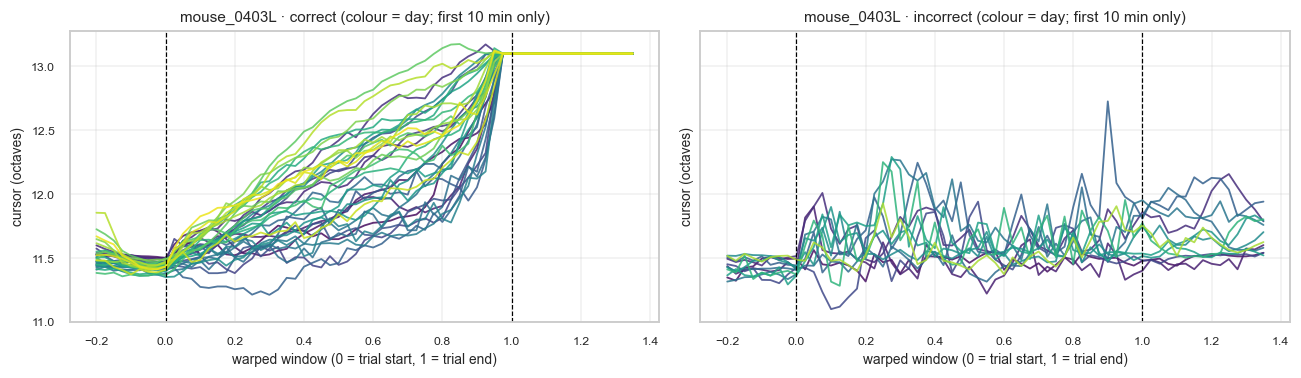

  [S3_day_shapes_mouse_0322R] saved (set FIG_LEVEL='full' to display)
  [S3_day_shapes_mouse_0403R] saved (set FIG_LEVEL='full' to display)


  [S3_day_shapes_mouse_0916N] saved (set FIG_LEVEL='full' to display)


In [3]:
AX = SPEC.axis()

def plot_day_shapes(mouse, outcome, ax, cmap="viridis", max_days=None):
    sub = comparable_subset(trials_df[(trials_df.mouse == mouse) & (trials_df.outcome == outcome)])
    days = sorted(sub.day.unique())
    if max_days: days = days[:max_days]
    pal = sns.color_palette(cmap, max(len(days), 2))
    for c, day in zip(pal, days):
        idx = sub.index[sub.day == day].to_numpy()
        if len(idx) < 3: continue
        ax.plot(AX, M_all[idx].mean(0), color=c, lw=1.2, alpha=0.85)
    ax.axvline(0, color="k", ls="--", lw=0.8); ax.axvline(1, color="k", ls="--", lw=0.8)
    ax.set(xlabel="warped window (0 = trial start, 1 = trial end)",
           ylabel=f"cursor ({'octaves' if CURSOR_TRANSFORM=='log2' else 'raw'})",
           title=f"{mouse} · {outcome} (colour = day; first {FIRST_MIN_FOR_DAY_COMPARISON:.0f} min only)")
    ax.grid(alpha=0.3)

for mouse in MICE:
    if (trials_df.mouse == mouse).sum() == 0: continue
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
    for ax, oc in zip(axes, ["correct", "incorrect"]):
        plot_day_shapes(mouse, oc, ax)
    show(fig, f"S3_day_shapes_{mouse}", per_mouse_level(mouse))

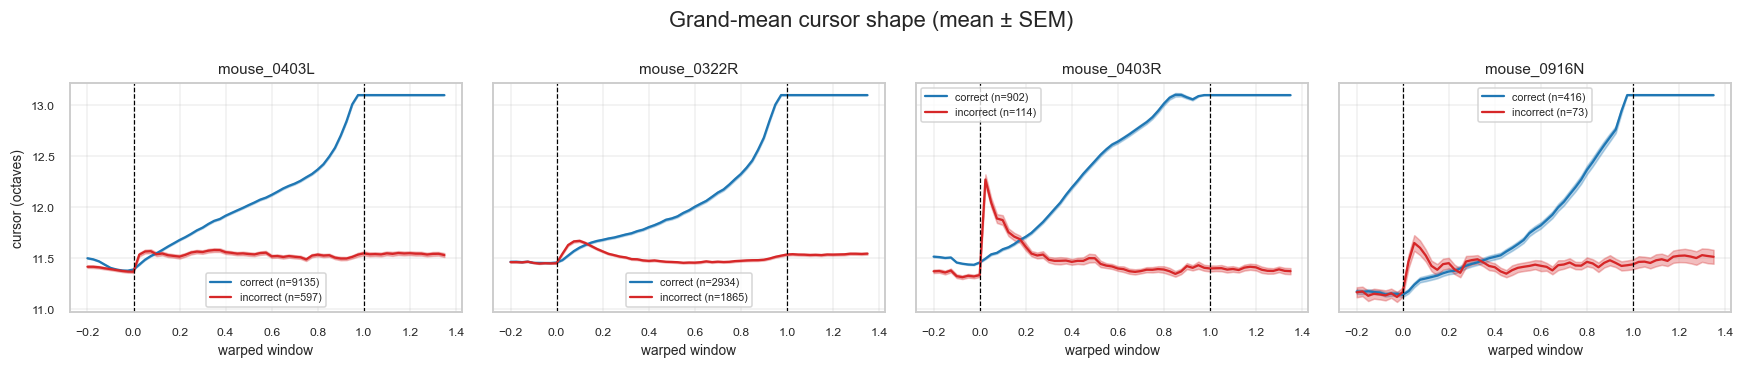

In [4]:
# grand mean +/- SEM per outcome, per mouse
fig, axes = plt.subplots(1, len(MICE), figsize=(4 * len(MICE), 3.4), sharey=True)
axes = np.atleast_1d(axes)
for ax, mouse in zip(axes, MICE):
    for oc, cc in OUTCOME_COLORS.items():
        idx = trials_df.index[(trials_df.mouse == mouse) & (trials_df.outcome == oc)].to_numpy()
        if len(idx) < 3: continue
        m, se = M_all[idx].mean(0), M_all[idx].std(0) / np.sqrt(len(idx))
        ax.plot(AX, m, color=cc, label=f"{oc} (n={len(idx)})")
        ax.fill_between(AX, m - se, m + se, color=cc, alpha=0.3)
    ax.axvline(0, color="k", ls="--", lw=0.8); ax.axvline(1, color="k", ls="--", lw=0.8)
    ax.set(title=mouse, xlabel="warped window"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
axes[0].set_ylabel(f"cursor ({'octaves' if CURSOR_TRANSFORM=='log2' else 'raw'})")
fig.suptitle("Grand-mean cursor shape (mean ± SEM)")
show(fig, "S3_grand_mean")

## 4 · Shape metrics across days and learning stages

Per-day median of each metric (medians because several metrics — `tortuosity`, `max_curvature` — are
heavy-tailed). `day_from0` counts days from the animal's day-0 (spontaneous) session, so 1 = first
BCI day. For the remapping animal the vertical line marks the first remapping day.

**Restriction (important):** every day contributes only its **first
`FIRST_MIN_FOR_DAY_COMPARISON` (10) minutes**. On a remapping day the rotation happens at ~11 min, so
this window lies entirely inside the pre-rotation **intuitive block** — meaning each point on these
curves describes intuitive-axis control on that day, never a mixture of intuitive / new-axis /
washout. Stable days are cut to the same window so time-on-task is matched too. The cell below
verifies that the restricted window really is all `intuitive_pre` on remapping days.

### What each metric means and how it is computed
`U` denotes the cursor's own unit — **octaves** here, because `CURSOR_TRANSFORM = "log2"` (so a
difference of 1 means a doubling of tone frequency). Metrics in the **shape** family are computed
after standardising each trial (time → [0, 1], cursor → z-score), which makes them independent of how
high or how loudly modulated the trial was; metrics in the **level** and **path** families keep their
physical units.

,family,meaning,computed_as,units
metric,,,,
pre_level,level,"Cursor level in the 2 s before the trial starts, i.e. the baseline pitch the animal is...",mean of the pre-trial flank (first `pre_n` columns).,U
peak,level,Highest cursor value reached during the trial.,max over the warped trial columns.,U
trough,level,Lowest cursor value during the trial.,min over the warped trial columns.,U
range,level,Total spread covered within the trial (modulation depth).,peak - trough.,U
mean_level,level,Average cursor level during the trial.,mean over the warped trial columns.,U
end_level,level,"Cursor value at the moment the trial ends (reward for hits, timeout for misses).",last warped trial column.,U
net_change,level,"How much higher the cursor ended than it started, relative to baseline.",end_level - pre_level.,U
post_drop,level,How far the cursor falls back in the 2 s after the trial ends.,end_level - mean(post-trial flank).,U
path_length,path,"Total up-and-down distance travelled across the whole window, including both flanks.",sum of |differences| between consecutive columns of the full window.,U


first 10 min of remapping days -> block composition: {'intuitive_pre': 749}
trials used per day (median): all=227, restricted=36


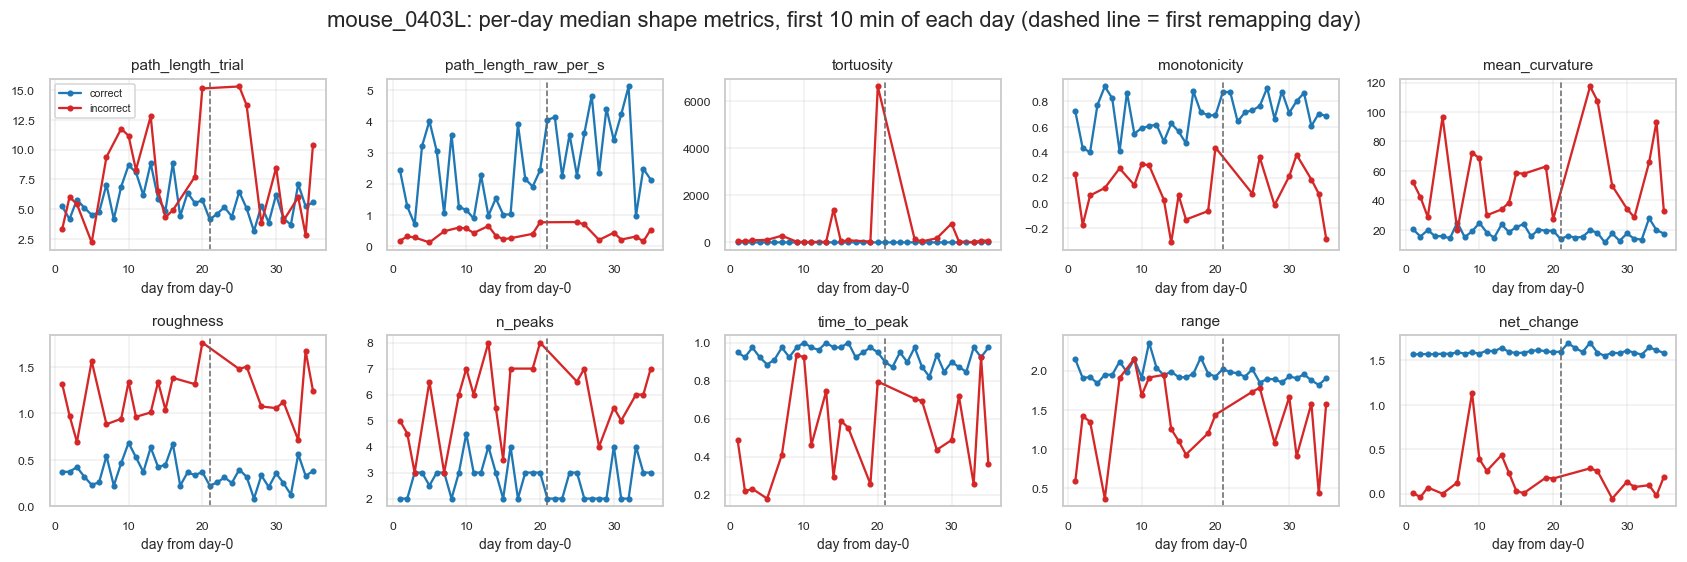

  [S4_metrics_days_mouse_0322R] saved (set FIG_LEVEL='full' to display)


  [S4_metrics_days_mouse_0403R] saved (set FIG_LEVEL='full' to display)


In [5]:
METRICS_SHOW = ["path_length_trial", "path_length_raw_per_s", "tortuosity", "monotonicity",
                "mean_curvature", "roughness", "n_peaks", "time_to_peak", "range", "net_change"]

# --- documentation of every metric (from cursor_analysis_utils) ---
pd.set_option("display.max_colwidth", 90)
display(ca.metric_description_table())

# --- verify the restricted window is pure intuitive-axis control on remapping days ---
chk_rm = comparable_subset(trials_df[trials_df.phase == "remap"])
print(f"first {FIRST_MIN_FOR_DAY_COMPARISON:.0f} min of remapping days -> block composition: "
      f"{chk_rm.block.value_counts().to_dict()}")
print(f"trials used per day (median): all={trials_df.groupby(['mouse','day']).size().median():.0f}, "
      f"restricted={comparable_subset(trials_df).groupby(['mouse','day']).size().median():.0f}")

def per_day_metric_table(mouse):
    sub = comparable_subset(trials_df[trials_df.mouse == mouse])
    return sub.groupby(["day_from0", "outcome"])[ca.SHAPE_METRIC_NAMES].median().reset_index()

for mouse in MICE:
    sub = comparable_subset(trials_df[trials_df.mouse == mouse])
    if sub.empty or sub.day.nunique() < 3: continue
    tab = per_day_metric_table(mouse)
    remap_start = sub.loc[sub.phase == "remap", "day_from0"].min() if (sub.phase == "remap").any() else None
    ncol = 5; nrow = int(np.ceil(len(METRICS_SHOW) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.1 * ncol, 2.6 * nrow))
    for ax, met in zip(np.atleast_1d(axes).ravel(), METRICS_SHOW):
        for oc, cc in OUTCOME_COLORS.items():
            t = tab[tab.outcome == oc]
            if t.empty: continue
            ax.plot(t.day_from0, t[met], "o-", ms=3, color=cc, label=oc)
        if remap_start is not None and np.isfinite(remap_start):
            ax.axvline(remap_start, color="0.4", ls="--", lw=1)
        ax.set(title=met, xlabel="day from day-0"); ax.grid(alpha=0.3)
    for ax in np.atleast_1d(axes).ravel()[len(METRICS_SHOW):]: ax.axis("off")
    np.atleast_1d(axes).ravel()[0].legend(fontsize=7)
    fig.suptitle(f"{mouse}: per-day median shape metrics, first {FIRST_MIN_FOR_DAY_COMPARISON:.0f} min of each day"
             f" (dashed line = first remapping day)")
    show(fig, f"S4_metrics_days_{mouse}", per_mouse_level(mouse))

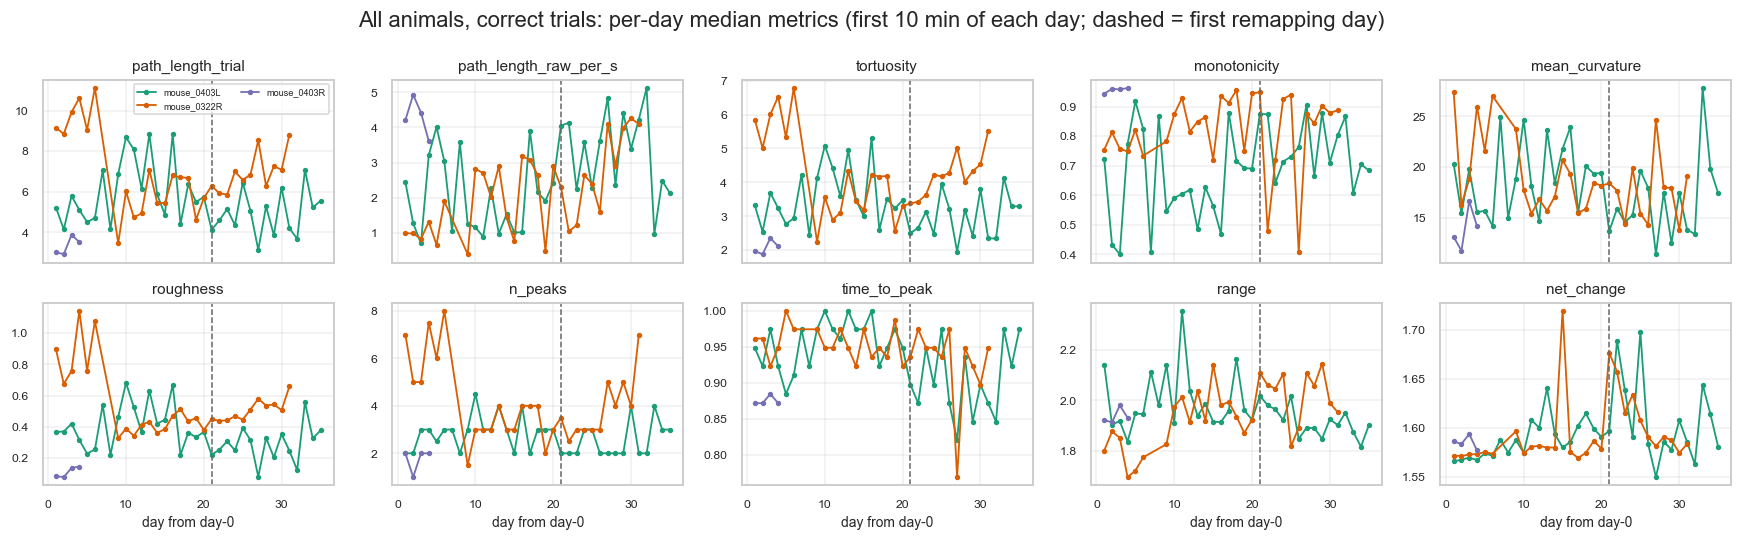

Spearman correlation of per-day median metric vs training day (stable-phase days,
first 10 min of each day).
No multiple-comparison correction is applied; treat p-values as descriptive.


mouse                 mouse_0322R           mouse_0403L          
outcome                   correct incorrect     correct incorrect
metric                                                           
end_level                     NaN      0.01         NaN      0.14
max_curvature               -0.32     -0.13        0.18     -0.12
mean_curvature              -0.34     -0.15        0.21     -0.03
mean_level                   0.10      0.39       -0.02      0.57
monotonicity                 0.29     -0.12        0.07     -0.05
n_peaks                     -0.19     -0.45        0.28      0.59
net_change                   0.56      0.15        0.78      0.32
path_length                 -0.10      0.02        0.37      0.42
path_length_raw_per_s        0.60      0.15       -0.08      0.37
path_length_trial           -0.15      0.15        0.30      0.37
peak                         0.41      0.30       -0.22      0.08
post_drop                     NaN      0.16         NaN      0.19
pre_level                   -0.56     -0.55       -0.78     -0.41
range                        0.59      0.27        0.12      0.04
roughness                   -0.08     -0.28        0.05      0.43
time_to_peak                -0.38     -0.23        0.34      0.38
tortuosity                  -0.12      0.40        0.18      0.07
trough                      -0.13      0.18       -0.49      0.13

In [6]:
# ---- compact cross-animal overview: one panel per metric, one line per animal ----
# Replaces having to read the four per-animal grids above side by side.
fig, axes = plt.subplots(2, 5, figsize=(16, 5.0), sharex=True)
pal = dict(zip(MICE, sns.color_palette("Dark2", len(MICE))))
for ax, met in zip(axes.ravel(), METRICS_SHOW):
    for mouse in MICE:
        sub = comparable_subset(trials_df[(trials_df.mouse == mouse) & (trials_df.outcome == "correct")])
        if sub.day.nunique() < 3: continue
        g = sub.groupby("day_from0")[met].median()
        ax.plot(g.index, g.values, "-o", ms=2.5, lw=1.2, color=pal[mouse], label=mouse)
    rs = trials_df.loc[trials_df.phase == "remap", "day_from0"]
    if len(rs): ax.axvline(rs.min(), color="0.4", ls="--", lw=1)
    ax.set(title=met); ax.grid(alpha=0.3)
for ax in axes[1]: ax.set_xlabel("day from day-0")
axes[0, 0].legend(fontsize=6, ncol=2)
fig.suptitle(f"All animals, correct trials: per-day median metrics "
             f"(first {FIRST_MIN_FOR_DAY_COMPARISON:.0f} min of each day; dashed = first remapping day)")
show(fig, "S4_overview_all_mice")

# does each metric change monotonically across the STABLE-phase days? (Spearman vs day)
rows = []
for mouse in MICE:
    sub = comparable_subset(trials_df[(trials_df.mouse == mouse) & (trials_df.phase == "stable")])
    if sub.day.nunique() < 5: continue
    for oc in ["correct", "incorrect"]:
        s = sub[sub.outcome == oc]
        if s.day.nunique() < 5: continue
        med = s.groupby("day_from0")[ca.SHAPE_METRIC_NAMES].median().reset_index()
        for met in ca.SHAPE_METRIC_NAMES:
            d = med[["day_from0", met]].dropna()
            if len(d) < 5: continue
            rho, p = spearmanr(d.day_from0, d[met])
            rows.append(dict(mouse=mouse, outcome=oc, metric=met, n_days=len(d), rho=rho, p=p))
day_trend = pd.DataFrame(rows)
print("Spearman correlation of per-day median metric vs training day (stable-phase days,")
print(f"first {FIRST_MIN_FOR_DAY_COMPARISON:.0f} min of each day).")
print("No multiple-comparison correction is applied; treat p-values as descriptive.")
display(day_trend.pivot_table(index="metric", columns=["mouse", "outcome"], values="rho").round(2))

## 5 · Within-day change: early / middle / late

**Stable-control days only.** On a remapping day, position-within-session is confounded with the
block structure (early = intuitive, middle = new axis, late = washout), so an early/middle/late split
there would just be re-measuring the blocks — which Section 6 does properly. This section therefore
uses `phase == "stable"` days, where the whole session is one control regime and the terciles really
do isolate time-on-task.

Trials are split into three equal-count groups by their time within the session. Shown as the mean
window per tercile (pooled over days, per mouse) and as per-tercile metric distributions, correct and
incorrect separately. A Kruskal–Wallis test across the three terciles is reported per metric — again
descriptive, with no correction for the number of metrics tested.

stable-phase trials: 11015 of 16036   (days: {'mouse_0322R': 30, 'mouse_0403L': 20, 'mouse_0403R': 4, 'mouse_0916N': 2})


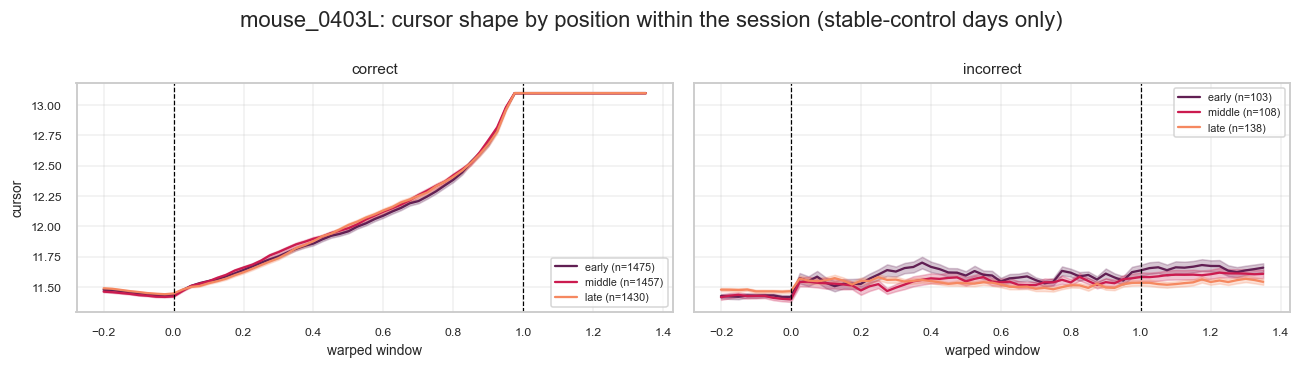

  [S5_tercile_shape_mouse_0322R] saved (set FIG_LEVEL='full' to display)
  [S5_tercile_shape_mouse_0403R] saved (set FIG_LEVEL='full' to display)


  [S5_tercile_shape_mouse_0916N] saved (set FIG_LEVEL='full' to display)


In [7]:
TERCILES = ["early", "middle", "late"]
TER_COLORS = dict(zip(TERCILES, sns.color_palette("rocket", 3)))

stable_df = trials_df[trials_df.phase == "stable"]
print(f"stable-phase trials: {len(stable_df)} of {len(trials_df)}"
      f"   (days: {stable_df.groupby('mouse').day.nunique().to_dict()})")

for mouse in MICE:
    sub = stable_df[stable_df.mouse == mouse]
    if sub.empty: continue
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
    for ax, oc in zip(axes, ["correct", "incorrect"]):
        for ter in TERCILES:
            idx = sub.index[(sub.outcome == oc) & (sub.tercile == ter)].to_numpy()
            if len(idx) < 5: continue
            m, se = M_all[idx].mean(0), M_all[idx].std(0) / np.sqrt(len(idx))
            ax.plot(AX, m, color=TER_COLORS[ter], label=f"{ter} (n={len(idx)})")
            ax.fill_between(AX, m - se, m + se, color=TER_COLORS[ter], alpha=0.25)
        ax.axvline(0, color="k", ls="--", lw=0.8); ax.axvline(1, color="k", ls="--", lw=0.8)
        ax.set(title=f"{oc}", xlabel="warped window"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
    axes[0].set_ylabel("cursor")
    fig.suptitle(f"{mouse}: cursor shape by position within the session (stable-control days only)")
    show(fig, f"S5_tercile_shape_{mouse}", per_mouse_level(mouse))

Kruskal-Wallis across early/middle/late terciles, STABLE-CONTROL DAYS ONLY
(descriptive; uncorrected).


,mouse,outcome,metric,p,med_early,med_middle,med_late
8,mouse_0403L,correct,path_length,0.0,5.9207,5.9598,5.0823
62,mouse_0322R,incorrect,path_length,0.0,7.3703,6.0099,5.0345
63,mouse_0322R,incorrect,path_length_trial,0.0,5.2631,4.1307,3.4046
64,mouse_0322R,incorrect,path_length_raw_per_s,0.0,0.2632,0.2065,0.1702
9,mouse_0403L,correct,path_length_trial,0.0,5.5223,5.4449,4.6424
11,mouse_0403L,correct,tortuosity,0.0,3.2321,3.2387,2.7734
55,mouse_0322R,incorrect,peak,0.0,12.3953,11.6822,11.6507
57,mouse_0322R,incorrect,range,0.0,1.3702,0.8560,0.6835
27,mouse_0403L,incorrect,path_length_trial,0.0,7.3182,5.3418,3.7056
28,mouse_0403L,incorrect,path_length_raw_per_s,0.0,0.3659,0.2671,0.1853


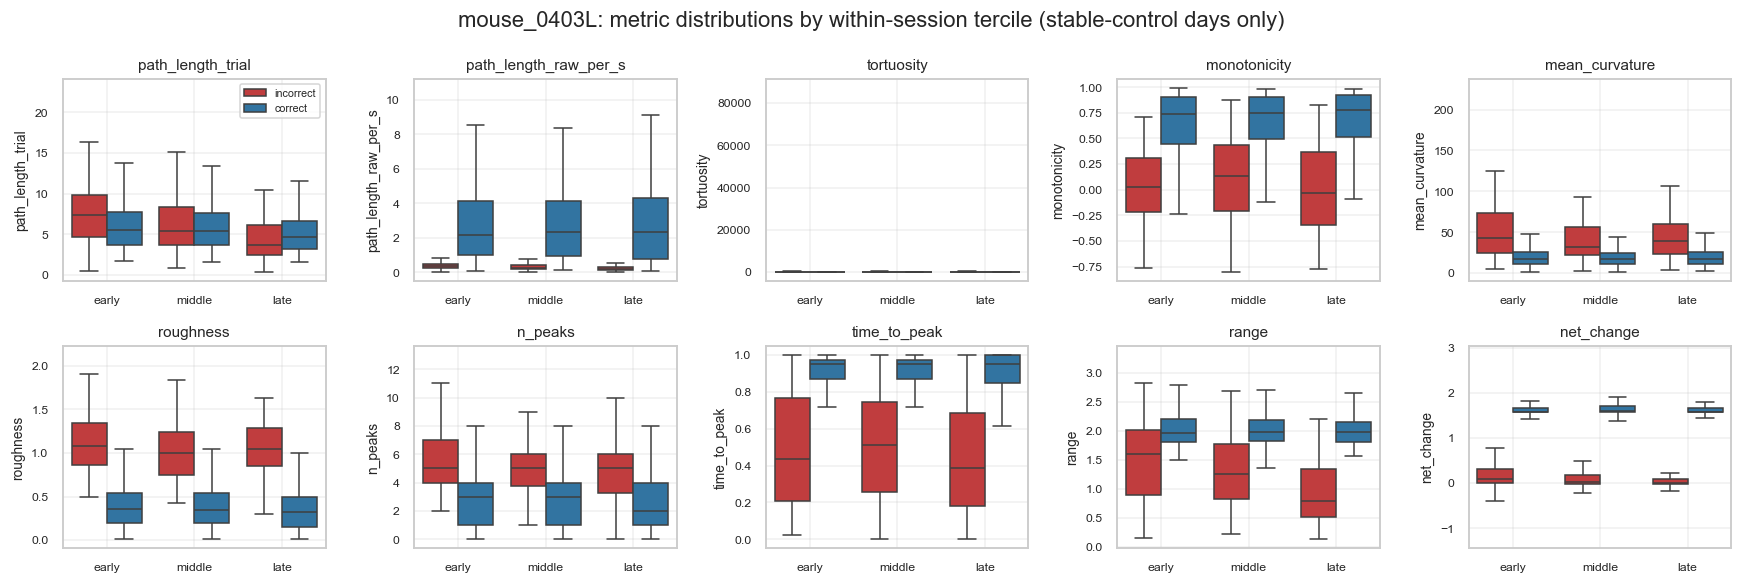

In [8]:
rows = []
for mouse in MICE:
    for oc in ["correct", "incorrect"]:
        s = stable_df[(stable_df.mouse == mouse) & (stable_df.outcome == oc)]
        if len(s) < 30: continue
        for met in ca.SHAPE_METRIC_NAMES:
            groups = [s.loc[s.tercile == t, met].dropna().to_numpy() for t in TERCILES]
            if min(len(g) for g in groups) < 5: continue
            try: H, p = kruskal(*groups)
            except Exception: continue
            rows.append(dict(mouse=mouse, outcome=oc, metric=met, p=p,
                             **{f"med_{t}": float(np.median(g)) for t, g in zip(TERCILES, groups)}))
ter_stats = pd.DataFrame(rows)
print("Kruskal-Wallis across early/middle/late terciles, STABLE-CONTROL DAYS ONLY")
print("(descriptive; uncorrected).")
display(ter_stats.sort_values("p").head(20).round(4))

m = CLUSTER_MOUSE
fig, axes = plt.subplots(2, 5, figsize=(16, 5.4))
for ax, met in zip(axes.ravel(), METRICS_SHOW):
    s = stable_df[stable_df.mouse == m]
    sns.boxplot(data=s, x="tercile", y=met, hue="outcome", order=TERCILES,
                palette=OUTCOME_COLORS, fliersize=0, ax=ax)
    ax.set(title=met, xlabel=""); ax.legend_.remove() if ax.legend_ else None; ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=7)
fig.suptitle(f"{m}: metric distributions by within-session tercile (stable-control days only)")
show(fig, f"S5_tercile_metrics_{m}")

## 6 · Remapping: intuitive-axis vs new-axis vs washout

On every remapping day the session is **(intuitive block, factor 2) → uncued rotation → (new block,
factor 3) → (washout, back to factor 2)**. The intuitive block is the ~10 min *before* the rotation.

**Stated caveat (do not read washout as a pure control):** the washout block is always last in the
session, so any difference there is confounded with time-on-task, satiety and motivation. For that
reason the washout block is additionally split into its own early/late halves, so a within-washout
drift can be seen directly.

mouse_0403L: 15 remapping days, 5021 trials


outcome,correct,incorrect
block,,
intuitive_pre,830,17
new,3433,165
washout,510,66


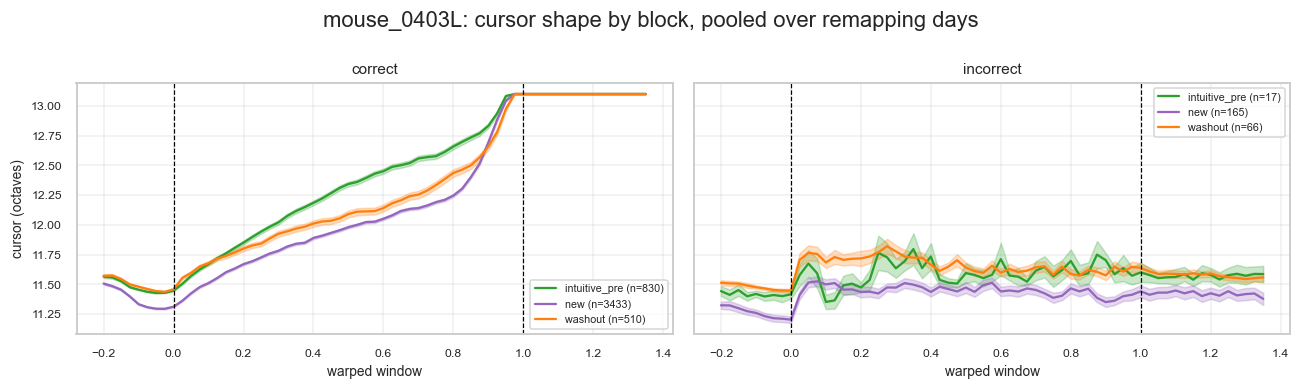

In [9]:
rm = trials_df[(trials_df.mouse == REMAP_MOUSE) & (trials_df.phase == "remap")].copy()
BLOCK_ORDER = ["intuitive_pre", "new", "washout"]
BLOCK_COLORS = {"intuitive_pre": "tab:green", "new": "tab:purple", "washout": "tab:orange"}
rm["remap_day"] = rm.day_from0 - rm.day_from0.min()
print(f"{REMAP_MOUSE}: {rm.day.nunique()} remapping days, {len(rm)} trials")
display(rm.groupby(["block", "outcome"]).size().unstack(fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, oc in zip(axes, ["correct", "incorrect"]):
    for blk in BLOCK_ORDER:
        idx = rm.index[(rm.outcome == oc) & (rm.block == blk)].to_numpy()
        if len(idx) < 5: continue
        m_, se = M_all[idx].mean(0), M_all[idx].std(0) / np.sqrt(len(idx))
        ax.plot(AX, m_, color=BLOCK_COLORS[blk], label=f"{blk} (n={len(idx)})")
        ax.fill_between(AX, m_ - se, m_ + se, color=BLOCK_COLORS[blk], alpha=0.25)
    ax.axvline(0, color="k", ls="--", lw=0.8); ax.axvline(1, color="k", ls="--", lw=0.8)
    ax.set(title=oc, xlabel="warped window"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
axes[0].set_ylabel("cursor (octaves)")
fig.suptitle(f"{REMAP_MOUSE}: cursor shape by block, pooled over remapping days")
show(fig, "S6_block_shape")

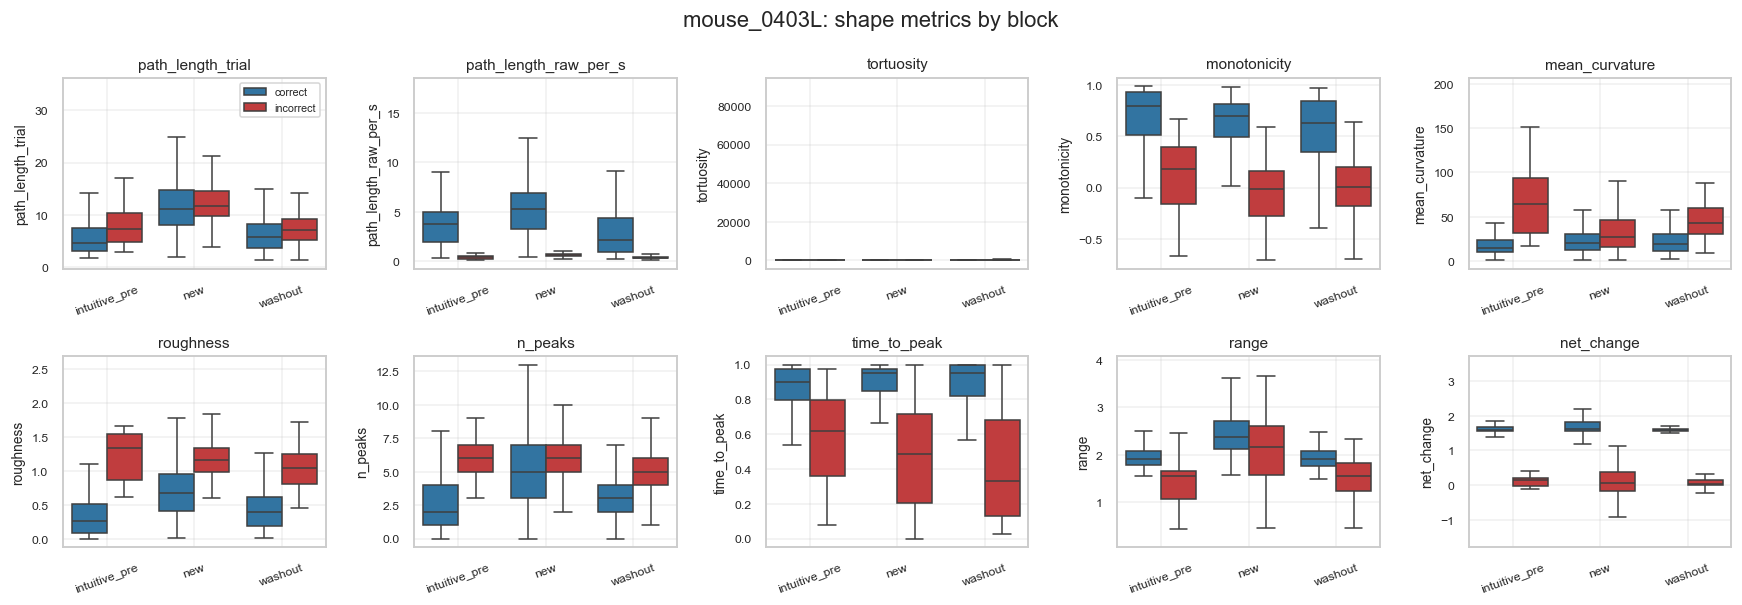

Mann-Whitney between blocks (descriptive, uncorrected). Washout comparisons are confounded
with time-on-task / motivation -- see the within-washout drift check below.


,outcome,metric,med_intuitive,med_new,med_washout,p_intuitive_vs_new,p_intuitive_vs_washout
0,correct,pre_level,11.5079,11.4845,11.5196,0.0000,0.0003
1,correct,peak,13.3062,13.4704,13.2433,0.0000,0.0000
2,correct,trough,11.4372,11.1446,11.3964,0.0000,0.0002
3,correct,range,1.9186,2.3771,1.9126,0.0000,0.5167
4,correct,mean_level,12.3683,12.0449,12.0398,0.0000,0.0000
5,correct,end_level,13.0995,13.0995,13.0995,1.0000,1.0000
6,correct,net_change,1.5916,1.6150,1.5800,0.0000,0.0003
7,correct,post_drop,0.0000,0.0000,0.0000,1.0000,1.0000
8,correct,path_length,5.3529,12.3464,6.2204,0.0000,0.0006
9,correct,path_length_trial,4.6374,11.1873,5.7425,0.0000,0.0001


In [10]:
# metric comparison between blocks, and the intuitive-vs-new test per outcome
fig, axes = plt.subplots(2, 5, figsize=(16, 5.6))
for ax, met in zip(axes.ravel(), METRICS_SHOW):
    sns.boxplot(data=rm, x="block", y=met, hue="outcome", order=BLOCK_ORDER,
                palette=OUTCOME_COLORS, fliersize=0, ax=ax)
    ax.set(title=met, xlabel="");
    if ax.legend_: ax.legend_.remove()
    ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=20)
axes[0, 0].legend(fontsize=7)
fig.suptitle(f"{REMAP_MOUSE}: shape metrics by block")
show(fig, "S6_block_metrics")

rows = []
for oc in ["correct", "incorrect"]:
    s = rm[rm.outcome == oc]
    for met in ca.SHAPE_METRIC_NAMES:
        a = s.loc[s.block == "intuitive_pre", met].dropna()
        b = s.loc[s.block == "new", met].dropna()
        w = s.loc[s.block == "washout", met].dropna()
        if min(len(a), len(b)) < 10: continue
        _, p_in = mannwhitneyu(a, b)
        p_iw = mannwhitneyu(a, w)[1] if len(w) >= 10 else np.nan
        rows.append(dict(outcome=oc, metric=met, med_intuitive=a.median(), med_new=b.median(),
                         med_washout=w.median() if len(w) else np.nan,
                         p_intuitive_vs_new=p_in, p_intuitive_vs_washout=p_iw))
block_stats = pd.DataFrame(rows)
print("Mann-Whitney between blocks (descriptive, uncorrected). Washout comparisons are confounded")
print("with time-on-task / motivation -- see the within-washout drift check below.")
display(block_stats.round(4))

,outcome,metric,med_early,med_late,p
0,correct,pre_level,11.5258,11.5123,0.0000
6,correct,net_change,1.5737,1.5872,0.0000
14,correct,roughness,0.3290,0.4842,0.0000
8,correct,path_length,5.5066,7.0405,0.0000
9,correct,path_length_trial,5.1051,6.3794,0.0000
10,correct,path_length_raw_per_s,3.1365,1.4380,0.0001
15,correct,monotonicity,0.6974,0.5680,0.0003
11,correct,tortuosity,3.1557,3.8072,0.0003
2,correct,trough,11.4121,11.3135,0.0003
4,correct,mean_level,12.1614,11.9302,0.0005


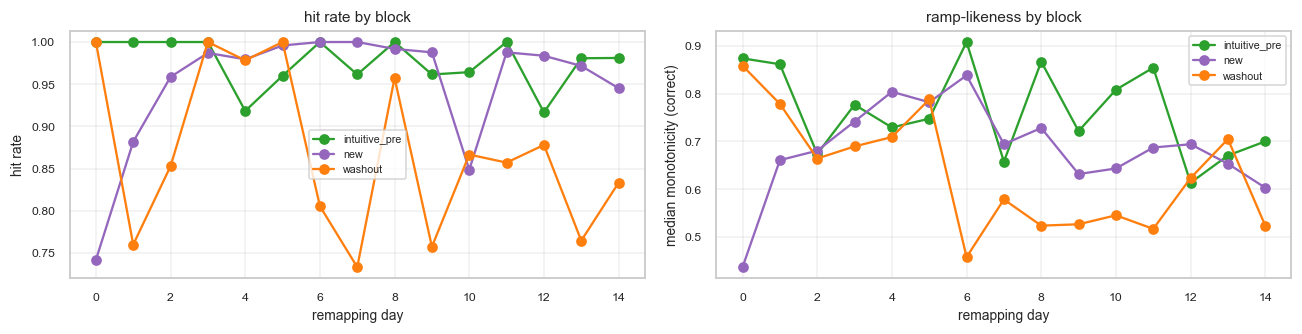

In [11]:
# within-washout drift (first vs second half of the washout block) -- the motivation check
wash = rm[rm.block == "washout"].copy()
wash["half"] = np.where(wash.k_in_block <= wash.groupby("day").k_in_block.transform("median"), "early", "late")
rows = []
for oc in ["correct", "incorrect"]:
    s = wash[wash.outcome == oc]
    for met in ca.SHAPE_METRIC_NAMES:
        a = s.loc[s.half == "early", met].dropna(); b = s.loc[s.half == "late", met].dropna()
        if min(len(a), len(b)) < 8: continue
        rows.append(dict(outcome=oc, metric=met, med_early=a.median(), med_late=b.median(),
                         p=mannwhitneyu(a, b)[1]))
wash_drift = pd.DataFrame(rows)
display(wash_drift.sort_values("p").round(4).head(12))

# hit rate per block per day: the behavioural context for the confound
hr = rm.groupby(["remap_day", "block"]).apply(lambda g: (g.outcome == "correct").mean()).unstack()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
hr[BLOCK_ORDER].plot(ax=axes[0], marker="o", color=[BLOCK_COLORS[b] for b in BLOCK_ORDER])
axes[0].set(xlabel="remapping day", ylabel="hit rate", title="hit rate by block")
axes[0].grid(alpha=0.3); axes[0].legend(fontsize=7)
for blk in BLOCK_ORDER:
    g = rm[(rm.block == blk) & (rm.outcome == "correct")].groupby("remap_day").monotonicity.median()
    axes[1].plot(g.index, g.values, "o-", color=BLOCK_COLORS[blk], label=blk)
axes[1].set(xlabel="remapping day", ylabel="median monotonicity (correct)", title="ramp-likeness by block")
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=7)
show(fig, "S6_block_by_day")

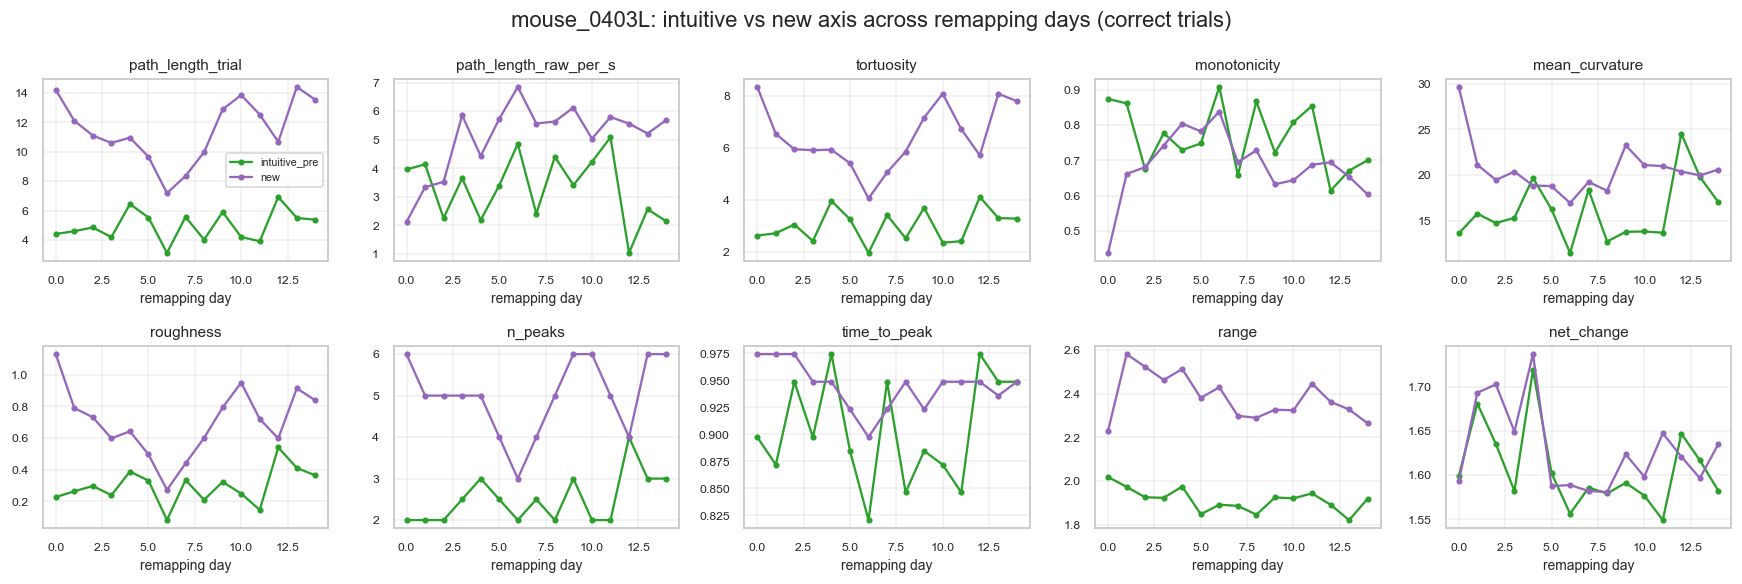

  [S6_first_last_day] saved (set FIG_LEVEL='full' to display)


In [12]:
# how does the intuitive-vs-new difference evolve across remapping days?
fig, axes = plt.subplots(2, 5, figsize=(16, 5.4))
for ax, met in zip(axes.ravel(), METRICS_SHOW):
    for blk in ["intuitive_pre", "new"]:
        g = rm[(rm.block == blk) & (rm.outcome == "correct")].groupby("remap_day")[met].median()
        ax.plot(g.index, g.values, "o-", ms=3, color=BLOCK_COLORS[blk], label=blk)
    ax.set(title=met, xlabel="remapping day"); ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=7)
fig.suptitle(f"{REMAP_MOUSE}: intuitive vs new axis across remapping days (correct trials)")
show(fig, "S6_intuitive_vs_new_days")

# and the mean shape on the first vs last remapping day
sel = [rm.remap_day.min(), rm.remap_day.max()]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, rd in zip(axes, sel):
    for blk in BLOCK_ORDER:
        idx = rm.index[(rm.remap_day == rd) & (rm.block == blk) & (rm.outcome == "correct")].to_numpy()
        if len(idx) < 5: continue
        ax.plot(AX, M_all[idx].mean(0), color=BLOCK_COLORS[blk], label=f"{blk} (n={len(idx)})")
    ax.axvline(0, color="k", ls="--", lw=0.8); ax.axvline(1, color="k", ls="--", lw=0.8)
    ax.set(title=f"remapping day {int(rd)}", xlabel="warped window"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
axes[0].set_ylabel("cursor (octaves)")
fig.suptitle(f"{REMAP_MOUSE}: correct-trial shape by block, first vs last remapping day")
show(fig, "S6_first_last_day", "full")

### 6b · The same comparison on individual remapping days

Pooling over all remapping days can hide a day-to-day change, so the block comparison is repeated
**separately for the remapping days listed in `REMAP_DAYS_TO_SHOW`** (day 0 = the first remapping day).
For each day: the mean cursor shape per block, and the per-block distribution of the shape metrics.
Correct and incorrect trials are kept separate, as everywhere else.

The washout caveat from Section 6 applies unchanged here — washout is always the last block of the
session, so any washout difference on a given day is confounded with time-on-task and motivation.

remapping days available: [np.int64(0), np.int64(1), np.int64(2)] ... 14   plotting: [0, 3, 7]


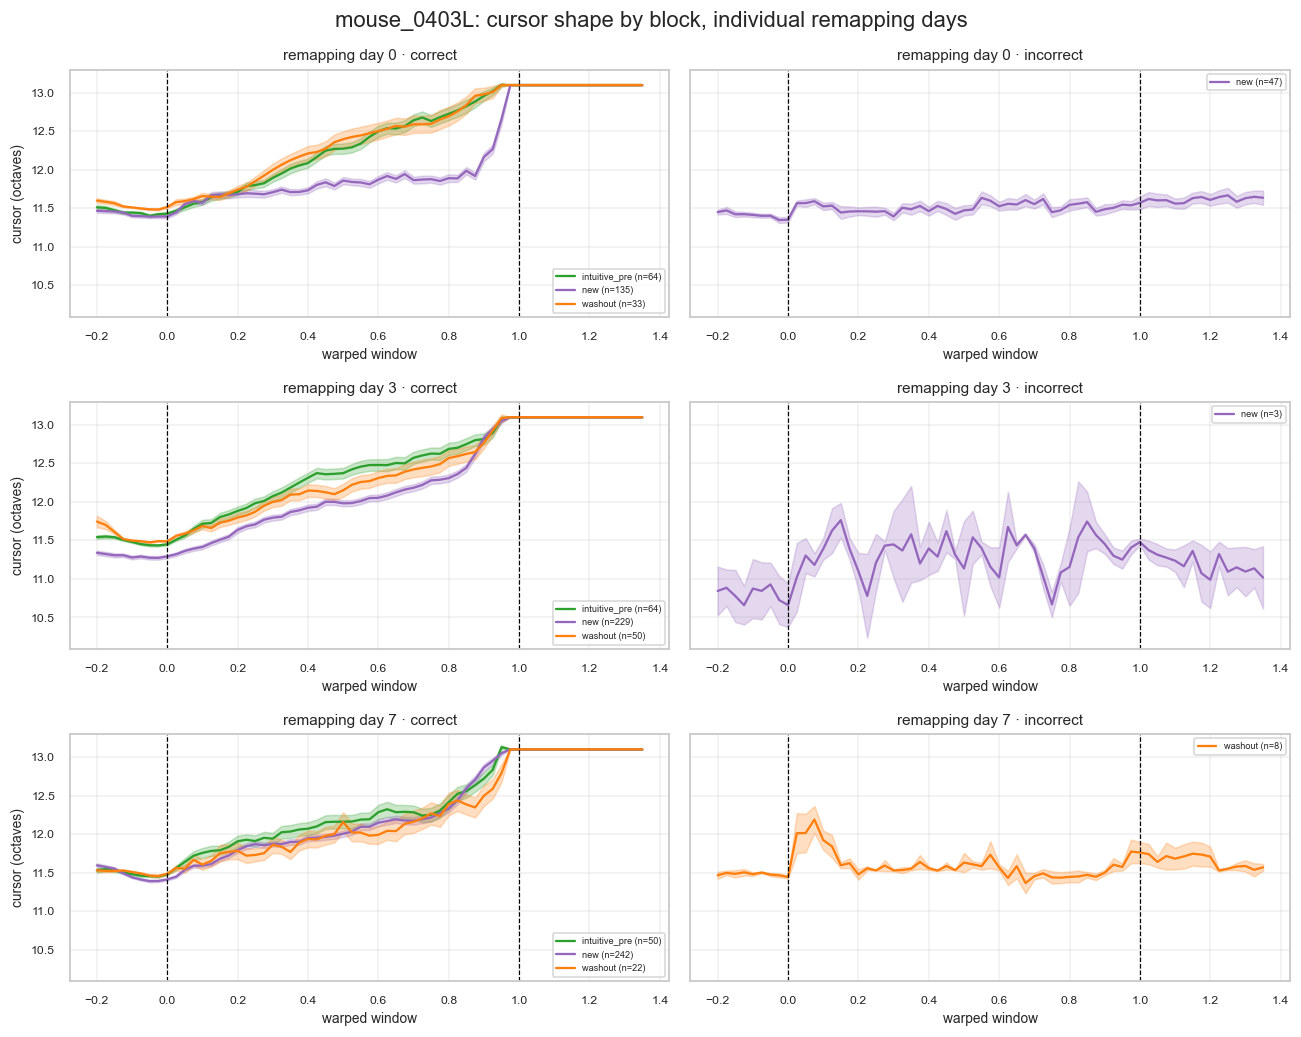

  [S6b_block_metrics_per_day_correct] saved (set FIG_LEVEL='full' to display)


  [S6b_block_metrics_per_day_incorrect] saved (set FIG_LEVEL='full' to display)
Intuitive vs new axis, tested separately within each selected remapping day
(Mann-Whitney, descriptive and uncorrected).


,remap_day,outcome,metric,n_int,n_new,med_intuitive,med_new,med_washout,p_intuitive_vs_new
0,0,correct,pre_level,64,135,11.5006,11.5067,11.5248,0.9611
1,0,correct,peak,64,135,13.4145,13.2919,13.3292,0.0494
2,0,correct,trough,64,135,11.3919,11.1221,11.4940,0.0000
3,0,correct,range,64,135,2.0188,2.2298,1.8125,0.0000
4,0,correct,mean_level,64,135,12.2751,11.8438,12.3927,0.0000
5,0,correct,end_level,64,135,13.0995,13.0995,13.0995,1.0000
6,0,correct,net_change,64,135,1.5990,1.5929,1.5747,0.9611
7,0,correct,post_drop,64,135,0.0000,0.0000,0.0000,1.0000
8,0,correct,path_length,64,135,4.7497,15.1617,4.1892,0.0000
9,0,correct,path_length_trial,64,135,4.4144,14.1939,3.6895,0.0000


In [13]:
days_present = sorted(rm.remap_day.unique())
show_days = [d for d in REMAP_DAYS_TO_SHOW if d in days_present]
print(f"remapping days available: {days_present[:3]} ... {days_present[-1]}   plotting: {show_days}")

# --- mean cursor shape per block, one row per selected day, correct vs incorrect ---
fig, axes = plt.subplots(len(show_days), 2, figsize=(12, 3.2 * len(show_days)), squeeze=False, sharey=True)
for r_, rd in enumerate(show_days):
    for c_, oc in enumerate(["correct", "incorrect"]):
        ax = axes[r_, c_]
        for blk in BLOCK_ORDER:
            idx = rm.index[(rm.remap_day == rd) & (rm.block == blk) & (rm.outcome == oc)].to_numpy()
            if len(idx) < 3: continue
            m_, se = M_all[idx].mean(0), M_all[idx].std(0) / np.sqrt(len(idx))
            ax.plot(AX, m_, color=BLOCK_COLORS[blk], label=f"{blk} (n={len(idx)})")
            ax.fill_between(AX, m_ - se, m_ + se, color=BLOCK_COLORS[blk], alpha=0.25)
        ax.axvline(0, color="k", ls="--", lw=0.8); ax.axvline(1, color="k", ls="--", lw=0.8)
        ax.set(title=f"remapping day {int(rd)} · {oc}", xlabel="warped window")
        ax.legend(fontsize=6); ax.grid(alpha=0.3)
    axes[r_, 0].set_ylabel(CURSOR_UNITS)
fig.suptitle(f"{REMAP_MOUSE}: cursor shape by block, individual remapping days")
show(fig, "S6b_block_shape_per_day")

# --- metrics by block, per selected day (correct trials; incorrect below) ---
for oc in ["correct", "incorrect"]:
    fig, axes = plt.subplots(len(show_days), len(METRICS_SHOW), figsize=(2.0 * len(METRICS_SHOW), 2.5 * len(show_days)),
                             squeeze=False)
    for r_, rd in enumerate(show_days):
        d = rm[(rm.remap_day == rd) & (rm.outcome == oc)]
        for c_, met in enumerate(METRICS_SHOW):
            ax = axes[r_, c_]
            if d.empty:
                ax.axis("off"); continue
            sns.boxplot(data=d, x="block", y=met, order=BLOCK_ORDER,
                        palette=[BLOCK_COLORS[b] for b in BLOCK_ORDER], fliersize=0, ax=ax)
            ax.set(title=met if r_ == 0 else "", xlabel="", ylabel=f"day {int(rd)}" if c_ == 0 else "")
            ax.set_xticklabels(["int", "new", "wash"], fontsize=6)
            ax.tick_params(axis="y", labelsize=6); ax.grid(alpha=0.3)
    fig.suptitle(f"{REMAP_MOUSE} · {oc}: shape metrics by block, individual remapping days")
    show(fig, f"S6b_block_metrics_per_day_{oc}", "full")

# --- intuitive vs new, tested within each selected day ---
rows = []
for rd in show_days:
    for oc in ["correct", "incorrect"]:
        d = rm[(rm.remap_day == rd) & (rm.outcome == oc)]
        for met in ca.SHAPE_METRIC_NAMES:
            a = d.loc[d.block == "intuitive_pre", met].dropna()
            b = d.loc[d.block == "new", met].dropna()
            w = d.loc[d.block == "washout", met].dropna()
            if min(len(a), len(b)) < 8: continue
            rows.append(dict(remap_day=int(rd), outcome=oc, metric=met, n_int=len(a), n_new=len(b),
                             med_intuitive=a.median(), med_new=b.median(),
                             med_washout=w.median() if len(w) else np.nan,
                             p_intuitive_vs_new=mannwhitneyu(a, b)[1]))
per_day_block_stats = pd.DataFrame(rows)
print("Intuitive vs new axis, tested separately within each selected remapping day")
print("(Mann-Whitney, descriptive and uncorrected).")
display(per_day_block_stats.round(4))

## 7 · Clustering cursor shapes

Pipeline, run **separately for correct and incorrect trials** of `CLUSTER_MOUSE`:

1. row-normalise the warped matrix (`NORMALIZE_MODE`),
2. **PCA**, keeping enough PCs to reach `PCA_VAR_TARGET` of the variance,
3. **Ward hierarchical clustering** on those PC scores,
4. choose `k` from a **silhouette scan** (the maximum, unless `N_CLUSTERS` is set) with the
   **dendrogram** shown alongside,
5. **t-SNE** and **UMAP** as 2-D views of the same PC scores.

The silhouette maximum is a heuristic for a *convenient* number of clusters, not evidence that the
data contain exactly that many groups.

In [14]:
def run_clustering(mouse, outcome, k=None):
    idx = trials_df.index[(trials_df.mouse == mouse) & (trials_df.outcome == outcome)].to_numpy()
    sub = trials_df.loc[idx].reset_index(drop=True).copy()
    X = ca.normalize_rows(M_all[idx], NORMALIZE_MODE)
    pr = ca.pca_reduce(X, PCA_VAR_TARGET)
    sil = ca.silhouette_scan(pr.scores, list(K_RANGE), seed=SEED)
    kk = k or (int(sil.loc[sil.silhouette.idxmax(), "k"]) if len(sil) else 3)
    lab = ca.hierarchical_labels(pr.scores, kk)
    sub["cluster"] = lab
    Z = ca.linkage_matrix(pr.scores)
    return dict(mouse=mouse, outcome=outcome, idx=idx, sub=sub, X=X, pca=pr,
                sil=sil, k=kk, labels=lab, linkage=Z)

CLU = {}
for oc in ["correct", "incorrect"]:
    t0 = time.time()
    CLU[oc] = run_clustering(CLUSTER_MOUSE, oc, k=N_CLUSTERS)
    c = CLU[oc]
    print(f"{oc:9s} n={len(c['idx']):5d}  PCs for {int(PCA_VAR_TARGET*100)}% var = {c['pca'].n_kept:3d}"
          f"  chosen k={c['k']}  cluster sizes={np.bincount(c['labels'])[1:]}  ({time.time()-t0:.1f}s)")

correct   n= 9135  PCs for 95% var =  24  chosen k=4  cluster sizes=[3520 2263 1164 2188]  (16.1s)
incorrect n=  597  PCs for 95% var =  37  chosen k=4  cluster sizes=[ 16 115  54 412]  (0.1s)


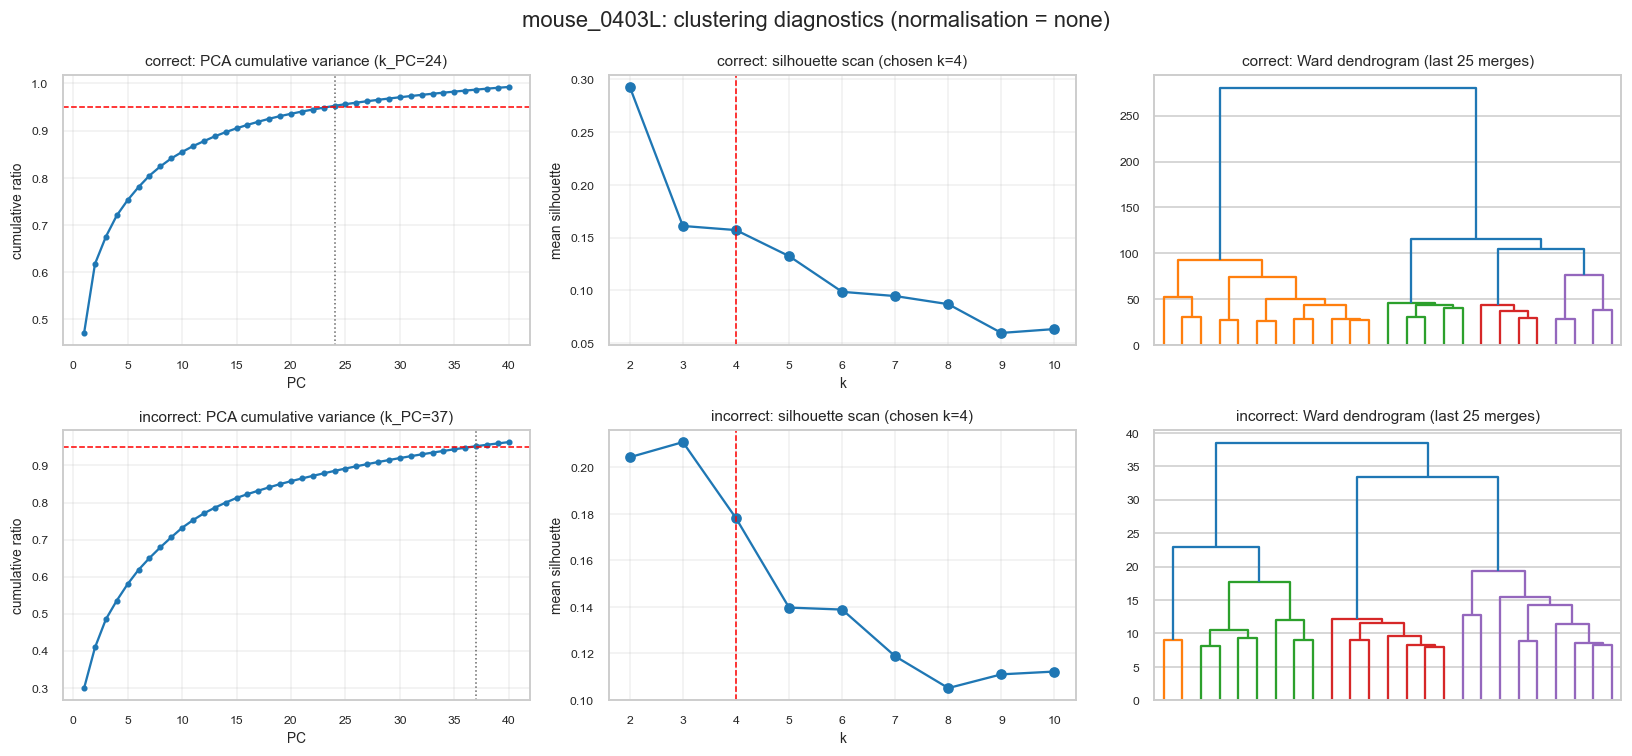

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for row, oc in enumerate(["correct", "incorrect"]):
    c = CLU[oc]
    ax = axes[row, 0]
    ev = c["pca"].explained_ratio
    ax.plot(np.arange(1, min(41, len(ev) + 1)), np.cumsum(ev)[:40], "o-", ms=3)
    ax.axhline(PCA_VAR_TARGET, color="r", ls="--", lw=1)
    ax.axvline(c["pca"].n_kept, color="0.4", ls=":", lw=1)
    ax.set(title=f"{oc}: PCA cumulative variance (k_PC={c['pca'].n_kept})",
           xlabel="PC", ylabel="cumulative ratio"); ax.grid(alpha=0.3)
    ax = axes[row, 1]
    ax.plot(c["sil"].k, c["sil"].silhouette, "o-")
    ax.axvline(c["k"], color="r", ls="--", lw=1)
    ax.set(title=f"{oc}: silhouette scan (chosen k={c['k']})", xlabel="k", ylabel="mean silhouette")
    ax.grid(alpha=0.3)
    ax = axes[row, 2]
    dendrogram(c["linkage"], truncate_mode="lastp", p=25, no_labels=True, ax=ax,
               color_threshold=c["linkage"][-(c["k"] - 1), 2] if c["k"] > 1 else None)
    ax.set(title=f"{oc}: Ward dendrogram (last 25 merges)")
fig.suptitle(f"{CLUSTER_MOUSE}: clustering diagnostics (normalisation = {NORMALIZE_MODE})")
show(fig, "S7_cluster_diagnostics")

In [16]:
c['k']

4

## 8 · What does each cluster look like?

Mean window per cluster (on the same normalisation used for clustering), plus each cluster's median
shape-metric profile and basic composition (trial duration, position in session).

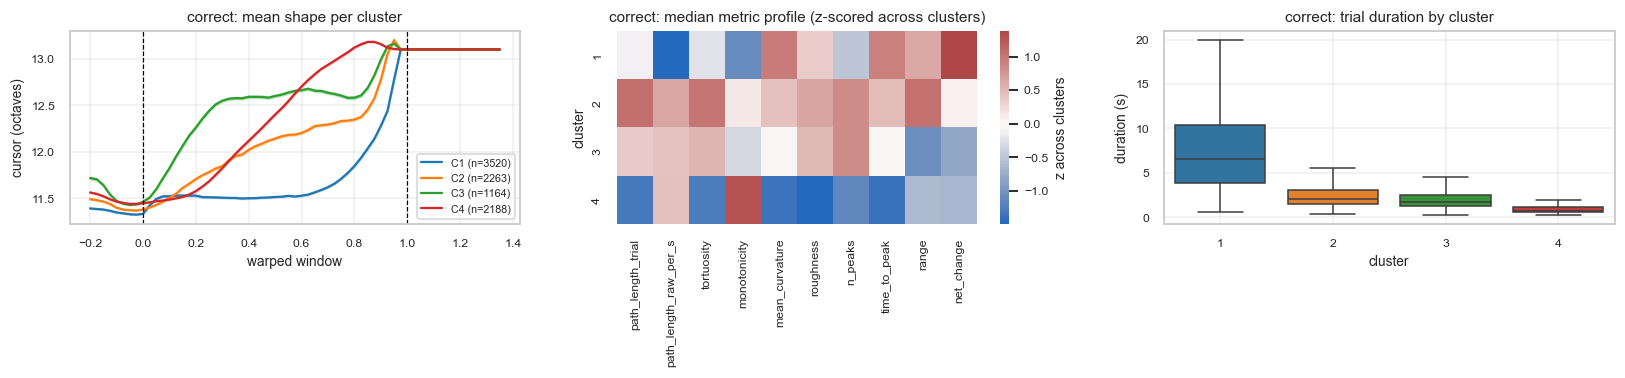

,duration_sec,path_length_trial,path_length_raw_per_s,tortuosity,monotonicity,mean_curvature,roughness,n_peaks,time_to_peak,range,net_change
cluster,,,,,,,,,,,
1,6.500,6.817,1.158,3.877,0.505,22.017,0.519,3.0,0.974,2.142,1.637
2,2.033,10.071,5.084,5.883,0.726,19.743,0.584,5.0,0.949,2.193,1.599
3,1.667,8.149,4.688,5.085,0.639,17.798,0.548,5.0,0.923,1.944,1.573
4,0.733,3.482,4.704,2.135,0.931,12.083,0.114,2.0,0.846,1.998,1.578


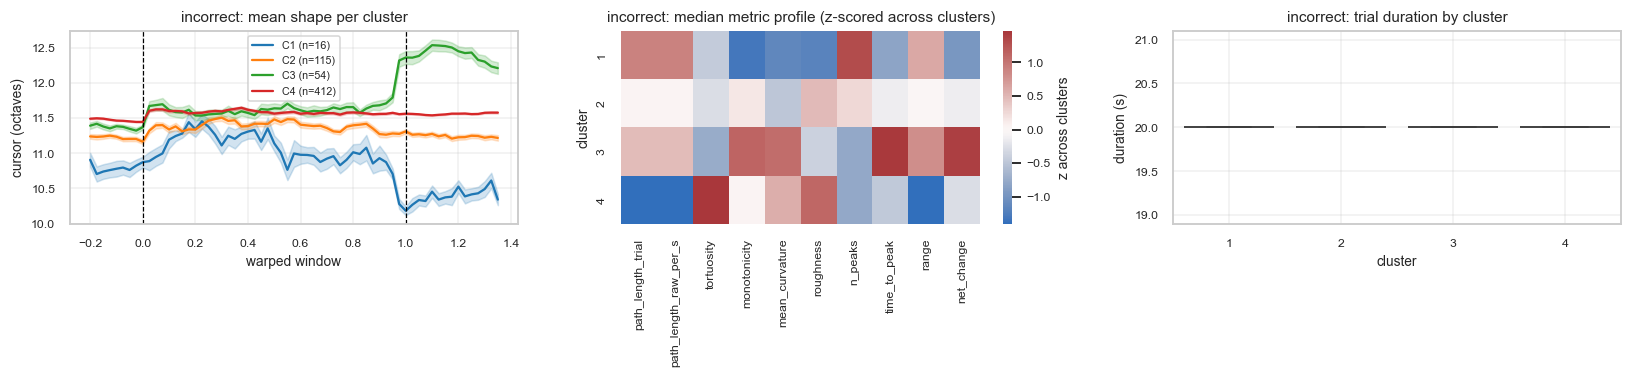

,duration_sec,path_length_trial,path_length_raw_per_s,tortuosity,monotonicity,mean_curvature,roughness,n_peaks,time_to_peak,range,net_change
cluster,,,,,,,,,,,
1,20.0,10.924,0.546,19.952,-0.228,18.651,0.928,7.0,0.321,1.900,-0.331
2,20.0,9.116,0.456,24.740,0.044,26.565,1.082,6.0,0.487,1.725,0.093
3,20.0,10.003,0.500,11.073,0.227,45.294,1.002,5.0,0.872,1.951,0.878
4,20.0,6.128,0.306,75.967,0.023,39.318,1.140,5.0,0.410,1.339,0.026


In [17]:
for oc in ["correct", "incorrect"]:
    c = CLU[oc]; sub, X = c["sub"], c["X"]
    ks = np.unique(c["labels"])
    pal = sns.color_palette("tab10", len(ks))
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    for col, kk in zip(pal, ks):
        sel = c["labels"] == kk
        m_, se = X[sel].mean(0), X[sel].std(0) / np.sqrt(sel.sum())
        axes[0].plot(AX, m_, color=col, label=f"C{kk} (n={sel.sum()})")
        axes[0].fill_between(AX, m_ - se, m_ + se, color=col, alpha=0.2)
    axes[0].axvline(0, color="k", ls="--", lw=0.8); axes[0].axvline(1, color="k", ls="--", lw=0.8)
    axes[0].set(title=f"{oc}: mean shape per cluster", xlabel="warped window",
                ylabel=CURSOR_UNITS); axes[0].legend(fontsize=7); axes[0].grid(alpha=0.3)
    prof = sub.groupby("cluster")[METRICS_SHOW].median()
    z = (prof - prof.mean()) / prof.std().replace(0, np.nan)
    sns.heatmap(z, cmap="vlag", center=0, ax=axes[1], cbar_kws=dict(label="z across clusters"))
    axes[1].set(title=f"{oc}: median metric profile (z-scored across clusters)", ylabel="cluster")
    sns.boxplot(data=sub, x="cluster", y="duration_sec", ax=axes[2], palette=list(pal), fliersize=0)
    axes[2].set(title=f"{oc}: trial duration by cluster", ylabel="duration (s)"); axes[2].grid(alpha=0.3)
    show(fig, f"S8_cluster_profile_{oc}")
    display(sub.groupby("cluster")[["duration_sec"] + METRICS_SHOW].median().round(3))

### 8b · How the clusters subdivide as `k` increases

The silhouette heuristic tends to favour the coarsest split (often `k = 2`), which can hide structure.
Here the same PCA scores are re-cut at several values of `k` so the hierarchy is visible: each panel
shows the mean window per cluster, with cluster sizes in the legend. Nothing below depends on this —
it is a sensitivity check on the single `k` chosen above.

In [18]:
for oc in ["correct", "incorrect"]:
    c = CLU[oc]
    fig, axes = plt.subplots(1, len(K_SENSITIVITY), figsize=(4 * len(K_SENSITIVITY), 3.3), sharey=True)
    for ax, kk in zip(np.atleast_1d(axes), K_SENSITIVITY):
        if kk >= len(c["sub"]):
            ax.axis("off"); continue
        lab = ca.hierarchical_labels(c["pca"].scores, kk)
        pal = sns.color_palette("tab10", kk)
        for j, u in enumerate(np.unique(lab)):
            sel = lab == u
            ax.plot(AX, c["X"][sel].mean(0), color=pal[j], lw=1.6, label=f"C{u} ({sel.sum()})")
        ax.axvline(0, color="k", ls="--", lw=0.8); ax.axvline(1, color="k", ls="--", lw=0.8)
        ax.set(title=f"k = {kk}", xlabel="warped window"); ax.legend(fontsize=6); ax.grid(alpha=0.3)
    np.atleast_1d(axes)[0].set_ylabel(CURSOR_UNITS)
    fig.suptitle(f"{CLUSTER_MOUSE} · {oc}: cluster mean shapes as k varies (chosen k = {c['k']})")
    show(fig, f"S8b_k_sensitivity_{oc}", "full")

    # how each k-cut distributes across blocks, for the remapping days
    rows = []
    rmx = c["sub"][c["sub"].phase == "remap"]
    for kk in K_SENSITIVITY:
        if kk >= len(c["sub"]): continue
        lab = ca.hierarchical_labels(c["pca"].scores, kk)
        tmp = c["sub"].assign(cl=lab)
        tmp = tmp[tmp.phase == "remap"]
        if tmp.empty: continue
        ct = pd.crosstab(tmp["block"], tmp["cl"])
        if ct.shape[0] > 1 and ct.shape[1] > 1:
            chi2, p, dof, _ = chi2_contingency(ct)
            rows.append(dict(outcome=oc, k=kk, chi2=chi2, dof=dof, p=p))
    if rows:
        print(f"{oc}: cluster x block association on remapping days, per k")
        display(pd.DataFrame(rows).round(4))

  [S8b_k_sensitivity_correct] saved (set FIG_LEVEL='full' to display)


correct: cluster x block association on remapping days, per k


,outcome,k,chi2,dof,p
0,correct,2,58.8722,2,0.0
1,correct,3,816.9231,4,0.0
2,correct,4,880.3280,6,0.0
3,correct,5,884.3642,8,0.0


  [S8b_k_sensitivity_incorrect] saved (set FIG_LEVEL='full' to display)
incorrect: cluster x block association on remapping days, per k


,outcome,k,chi2,dof,p
0,incorrect,2,45.9301,2,0.0
1,incorrect,3,52.5036,4,0.0
2,incorrect,4,52.5848,6,0.0
3,incorrect,5,63.7125,8,0.0


### 8c · The same clusters, in **brain-cursor** units

The clusters above are built from `freqToOutput`, the tone the animal hears. That signal has a
property worth knowing about: **during reward delivery the task stops rendering the cursor as pitch
and clamps the speaker to a fixed reward tone** — `frequencyOverride` (frame-for-frame identical to
`CE_rewardDelivery`) holds the output at exactly **8777.2 Hz = 13.100 octaves** for ~0.97 s, in every
animal measured.

That explains two features of the mean shapes:

* the **flat plateau at 13.100** is the reward tone, not the animal holding the cursor steady;
* the **dip just before it** is the step onto that tone. At threshold crossing the tone is *higher*
  than the reward tone (median 13.32 oct in `mouse_0403L`, up to 13.53 in other animals), so when
  the override engages the trace steps **down** by 0.2–0.4 octaves. The cursor is not coming back
  down — the audio simply stopped following it. Reward is still delivered at threshold crossing.

Because trial end is the reward frame and the override starts slightly before it, the clamp eats the
end of every correct trial, and it eats proportionally *more* of a short trial: the reward tone
(~0.97 s) is longer than an entire cluster-4 trial (median 0.73 s).

**This section re-plots the identical clusters using the decoder's own output instead.**
`cursor_brain` is the scalar obtained by applying the decoder mapping to the neural activity, before
the exponential transformation into a frequency — and it is **not** overridden (measured: 4931
distinct values during reward delivery, versus exactly 1 for `freqToOutput`). Nothing else changes:
same trials, same trial indices, same start/end frames, same time-warping, same cluster labels. Only
the signal being averaged is swapped.

Two reading traps, both handled below:

1. The **trial-averaged** brain cursor peaks *below* the reward threshold, because averaging
   smears the crossing time across trials that cross at slightly different moments. The table
   reports the per-trial figure instead, and takes it from the **raw** trace rather than the
   warped one — time-warping here interpolates, so a 6.5 s trial warped to 40 bins keeps only
   ~1 frame in 5 and loses brief crossings, in a duration-biased way.
2. **The two decoders have different reward thresholds.** On remapping days the task runs
   factor 2 (intuitive) and factor 3 (new axis) and gives them **different bars**: measured here,
   factor 2 -> **1.9**, factor 3 -> **0.9**, with the quiescence thresholds scaled the same way
   (0.19 vs 0.09). Judged against its own threshold, `cursor_brain` clears the bar on **~99 % of
   the task's own threshold-crossing frames for both decoders**, so it is one consistent scale --
   the new axis simply requires less. Each factor panel draws its own threshold, and the table
   adds `brain_peak_over_thresh` (peak in units of that decoder's threshold), which is the
   quantity that *is* comparable across factors.

Units are the decoder's own (roughly z-like, and legitimately negative), so **no log transform is
applied** here. The dashed line marks `cursor_threshold_reward`, the value a trial must reach to
earn reward. `BRAIN_COLUMN` can be set to `"cursor_output"` (the same signal after the task's
clipping) to compare.

In [19]:
BRAIN_COLUMN = "cursor_brain"   # decoder output BEFORE the exponential mapping to frequency
                                # ("cursor_output" = the same after the task's clipping)

# Rebuild the window matrix for the brain cursor over EXACTLY the same trials and windows as M.
# Rows are aligned to trials_df.index, so the cluster labels from Section 7 apply unchanged.
def _aligned_windows(column, transform):
    '''Warped windows aligned to trials_df.index, plus the per-trial max of the RAW signal.

    The raw max is kept because the warped matrix must not be used for peak-like quantities:
    time-warping here interpolates, so a long trial warped to N_TRIAL_BINS is SUBSAMPLED (a 6.5 s
    trial keeps ~1 frame in 5) and brief excursions are lost, while a short trial is upsampled and
    keeps everything. Any peak read off the warped trace is therefore duration-biased.'''
    out = np.full((len(trials_df), SPEC.n_cols), np.nan)
    raw_max = np.full(len(trials_df), np.nan)
    for (mouse, day), g in trials_df.groupby(["mouse", "day"]):
        r_ = na.open_mouse(rfs, DATA_ROOT, mouse)
        try:
            sig = (ca.load_reward_override(r_, day) if column == "__override__"
                   else ca.load_cursor_signal(r_, day, column=column, transform=transform,
                                              max_gap_sec=MAX_GAP_SEC, sr=SR))
        except Exception as e:
            print(f"  {mouse} {day}: {type(e).__name__}"); continue
        W, kept, _ = ca.extract_trial_windows(sig, g.start_frame.to_numpy(), g.end_frame.to_numpy(),
                                              SPEC, max_nan_frac=MAX_NAN_FRAC)
        if len(kept):
            out[g.index.to_numpy()[kept]] = W
        for i_, a_, b_ in zip(g.index.to_numpy(), g.start_frame.to_numpy().astype(int),
                              g.end_frame.to_numpy().astype(int)):
            if 0 <= a_ < b_ <= len(sig):
                seg = sig[a_:b_]
                if np.isfinite(seg).any():
                    raw_max[i_] = np.nanmax(seg)
    return out, raw_max

bfp = OUT / f"Mbrain_{BRAIN_COLUMN}_{TAG}.npy"
ofp = OUT / f"Movr_{TAG}.npy"
rfp = OUT / f"BrainMaxRaw_{BRAIN_COLUMN}_{TAG}.npy"
if USE_CACHE and bfp.exists() and ofp.exists() and rfp.exists():
    M_BRAIN, M_OVR, BRAIN_MAX_RAW = np.load(bfp), np.load(ofp), np.load(rfp)
else:
    t0 = time.time()
    M_BRAIN, BRAIN_MAX_RAW = _aligned_windows(BRAIN_COLUMN, None)
    M_OVR, _ = _aligned_windows("__override__", None)
    np.save(bfp, M_BRAIN); np.save(ofp, M_OVR); np.save(rfp, BRAIN_MAX_RAW)
    print(f"built in {time.time()-t0:.0f}s")

ok_brain = np.isfinite(M_BRAIN).all(axis=1)
print(f"{BRAIN_COLUMN}: {ok_brain.sum()}/{len(trials_df)} trials extracted "
      f"({100*ok_brain.mean():.1f} %) over the same windows as the tone-based matrix")

# Reward thresholds, read from the task logger per DECODER FACTOR. Remapping days run two
# decoders and give them different thresholds, so a single per-day number is wrong there.
_r = na.open_mouse(rfs, DATA_ROOT, CLUSTER_MOUSE)
_days = sorted(trials_df.loc[trials_df.mouse == CLUSTER_MOUSE, "day"].unique())
_by_day = [ca.reward_threshold_by_factor(_r, d) for d in _days]
THRESH_BY_FACTOR = {f: float(np.median([d[f] for d in _by_day if f in d]))
                    for f in sorted({f for d in _by_day for f in d})}
print(f"{CLUSTER_MOUSE}: reward threshold per decoder factor = "
      + ", ".join(f"factor {f:g} -> {t:g}" for f, t in THRESH_BY_FACTOR.items()))
THRESH_PER_TRIAL = trials_df["factor"].map(THRESH_BY_FACTOR).to_numpy(dtype=float)
_ok = np.isfinite(BRAIN_MAX_RAW) & np.isfinite(THRESH_PER_TRIAL)
print(f"trials whose RAW brain cursor reaches their OWN factor's threshold: "
      f"{100*np.mean(BRAIN_MAX_RAW[_ok] >= THRESH_PER_TRIAL[_ok]):.1f}%")
_tr = trials_df.index[(trials_df.mouse == CLUSTER_MOUSE) & (trials_df.outcome == "correct")].to_numpy()
print(f"reward-tone clamp covers {100*np.nanmean(M_OVR[_tr][:, SPEC.trial_slice]):.1f}% of the warped "
      f"trial and {100*np.nanmean(M_OVR[_tr][:, SPEC.pre_n+N_TRIAL_BINS:]):.1f}% of the post-flank "
      f"(correct trials)")

built in 14s
cursor_brain: 16036/16036 trials extracted (100.0 %) over the same windows as the tone-based matrix


mouse_0403L: reward threshold per decoder factor = factor 2 -> 1.9, factor 3 -> 0.9
trials whose RAW brain cursor reaches their OWN factor's threshold: 85.0%
reward-tone clamp covers 5.3% of the warped trial and 99.5% of the post-flank (correct trials)


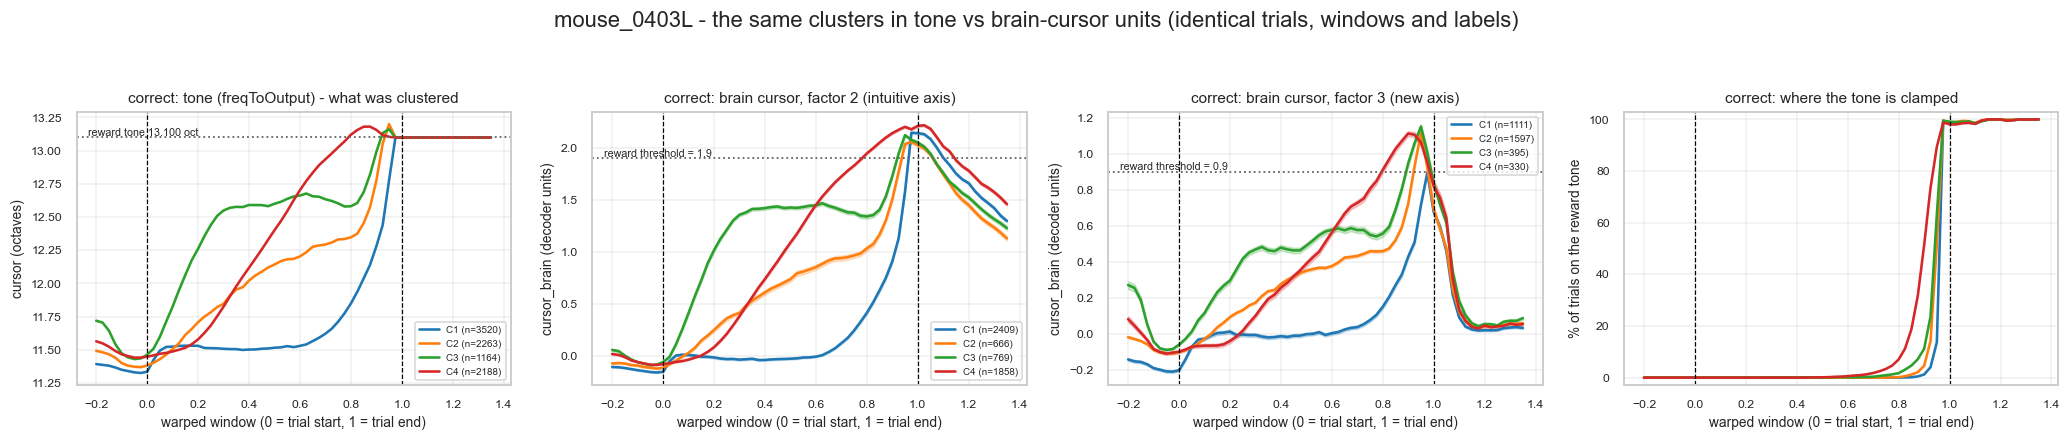

  [S8c_brain_cursor_incorrect] saved (set FIG_LEVEL='full' to display)
Correct-trial clusters, split by decoder factor (2 = intuitive axis, 3 = new axis).
The tone ends at exactly 13.100 for every cluster because that is the reward tone, not behaviour.
The two decoders have DIFFERENT reward thresholds (factor 2 -> 1.9, factor 3 -> 0.9), so each
trial is judged against its own. `pct_reaching_own_thresh` is ~99 % on BOTH, so the lower
factor-3 amplitudes are a lower BAR, not a different scale. Use `brain_peak_over_thresh`
(peak in units of that decoder's threshold) to compare across factors.


,cluster,factor,n,median_dur_s,brain_peak,brain_at_trial_end,brain_end_minus_peak,thresh,brain_peak_over_thresh,pct_reaching_own_thresh,pct_trial_clamped
0,1,2,2409,6.800,2.147,2.147,0.000,1.9,1.130,99.668,2.891
1,1,3,1111,5.867,0.895,0.895,0.000,0.9,0.995,100.000,3.172
2,2,2,666,2.417,2.059,2.059,0.000,1.9,1.084,99.700,4.310
3,2,3,1597,1.933,1.117,0.924,-0.193,0.9,1.241,100.000,4.364
4,3,2,769,1.800,2.124,2.078,-0.046,1.9,1.118,99.870,5.417
5,3,3,395,1.500,1.151,1.007,-0.144,0.9,1.279,100.000,5.623
6,4,2,1858,0.700,2.204,2.180,-0.024,1.9,1.160,99.677,10.013
7,4,3,330,0.800,1.113,0.954,-0.159,0.9,1.236,100.000,9.718


In [20]:
FACTORS = [2.0, 3.0]          # 2 = intuitive-axis decoder, 3 = the rotated (new-axis) decoder
FACTOR_LABEL = {2.0: "factor 2 (intuitive axis)", 3.0: "factor 3 (new axis)"}

for oc in ["correct", "incorrect"]:
    c = CLU[oc]
    idx, labs = c["idx"], c["labels"]                 # identical trials + labels as Section 7/8
    ks = np.unique(labs)
    pal = sns.color_palette("tab10", len(ks))
    fac_all = trials_df.loc[idx, "factor"].to_numpy()
    fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))

    for col, kk in zip(pal, ks):
        sel = labs == kk
        rows = idx[sel]
        axes[0].plot(AX, np.nanmean(M_all[rows], axis=0), color=col, lw=1.7,
                     label=f"C{kk} (n={sel.sum()})")
        # brain cursor, split by decoder factor -- the two are on DIFFERENT SCALES (see markdown)
        for ax, f in zip(axes[1:3], FACTORS):
            r_f = idx[sel & (fac_all == f)]
            B = M_BRAIN[r_f]; B = B[np.isfinite(B).all(axis=1)]
            if len(B) < 5: continue
            mb, sb = B.mean(0), B.std(0) / np.sqrt(len(B))
            ax.plot(AX, mb, color=col, lw=1.7, label=f"C{kk} (n={len(B)})")
            ax.fill_between(AX, mb - sb, mb + sb, color=col, alpha=0.22)
        axes[3].plot(AX, 100 * np.nanmean(M_OVR[rows], axis=0), color=col, lw=1.7)

    for ax in axes:
        ax.axvline(0, color="k", ls="--", lw=0.8); ax.axvline(1, color="k", ls="--", lw=0.8)
        ax.set_xlabel("warped window (0 = trial start, 1 = trial end)"); ax.grid(alpha=0.3)
    axes[0].axhline(np.log2(8777.2), color="0.4", ls=":", lw=1.2)
    axes[0].text(0.02, np.log2(8777.2), " reward tone 13.100 oct", fontsize=7, va="bottom",
                 transform=axes[0].get_yaxis_transform())
    axes[0].set(ylabel="cursor (octaves)", title=f"{oc}: tone (freqToOutput) - what was clustered")
    axes[0].legend(fontsize=6.5)
    for ax, f in zip(axes[1:3], FACTORS):
        ax.set(ylabel=f"{BRAIN_COLUMN} (decoder units)", title=f"{oc}: brain cursor, {FACTOR_LABEL[f]}")
        ax.legend(fontsize=6.5)
    for ax, f in zip(axes[1:3], FACTORS):           # each decoder has its OWN threshold
        th = THRESH_BY_FACTOR.get(f, np.nan)
        if np.isfinite(th):
            ax.axhline(th, color="0.4", ls=":", lw=1.2)
            ax.text(0.02, th, f" reward threshold = {th:g}", fontsize=7, va="bottom",
                    transform=ax.get_yaxis_transform())
    axes[3].set(ylabel="% of trials on the reward tone", ylim=(-3, 103),
                title=f"{oc}: where the tone is clamped")
    fig.suptitle(f"{CLUSTER_MOUSE} - the same clusters in tone vs brain-cursor units "
                 f"(identical trials, windows and labels)", y=1.05)
    show(fig, f"S8c_brain_cursor_{oc}", "summary" if oc == "correct" else "full")

# numbers behind the figure, per cluster AND per decoder factor
c = CLU["correct"]; rows_ = []
fac_all = trials_df.loc[c["idx"], "factor"].to_numpy()
ts_ = SPEC.trial_slice
for kk in np.unique(c["labels"]):
    for f in FACTORS:
        sel = (c["labels"] == kk) & (fac_all == f)
        if sel.sum() < 5: continue
        ridx = c["idx"][sel]
        B = M_BRAIN[ridx]; B = B[np.isfinite(B).all(axis=1)]
        brain = B.mean(0) if len(B) else np.full(SPEC.n_cols, np.nan)
        rows_.append(dict(cluster=kk, factor=int(f), n=int(sel.sum()),
                          median_dur_s=float(trials_df.loc[ridx, "duration_sec"].median()),
                          brain_peak=float(np.nanmax(brain[ts_])),
                          brain_at_trial_end=float(brain[SPEC.pre_n + N_TRIAL_BINS - 1]),
                          brain_end_minus_peak=float(brain[SPEC.pre_n + N_TRIAL_BINS - 1] - np.nanmax(brain[ts_])),
                          # from the RAW trace: warping interpolates and so subsamples long trials
                          thresh=float(THRESH_BY_FACTOR.get(f, np.nan)),
                          brain_peak_over_thresh=float(np.nanmax(brain[ts_]) / THRESH_BY_FACTOR.get(f, np.nan)),
                          pct_reaching_own_thresh=float(100 * np.nanmean(BRAIN_MAX_RAW[ridx] >= THRESH_BY_FACTOR.get(f, np.nan))),
                          pct_trial_clamped=float(100 * np.nanmean(M_OVR[ridx][:, ts_]))))
print("Correct-trial clusters, split by decoder factor (2 = intuitive axis, 3 = new axis).")
print("The tone ends at exactly 13.100 for every cluster because that is the reward tone, not behaviour.")
print("The two decoders have DIFFERENT reward thresholds (factor 2 -> 1.9, factor 3 -> 0.9), so each")
print("trial is judged against its own. `pct_reaching_own_thresh` is ~99 % on BOTH, so the lower")
print("factor-3 amplitudes are a lower BAR, not a different scale. Use `brain_peak_over_thresh`")
print("(peak in units of that decoder's threshold) to compare across factors.")
display(pd.DataFrame(rows_).round(3))

## 9 · Cluster membership across days, phases and within-day period

For each grouping, rows are the group and columns the clusters; **each row sums to 1**, so the values
are the fraction of that group's trials falling in each cluster. Chi-square tests of independence are
reported as descriptive summaries (they are sensitive to the large trial counts here).

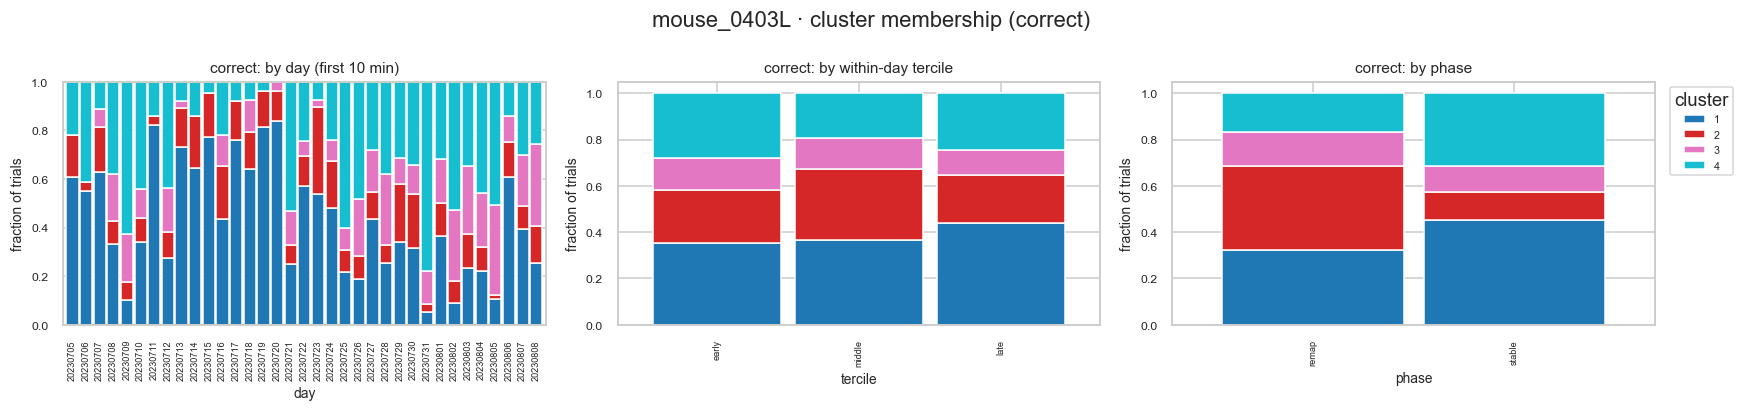

  correct   cluster x day     : chi2=   2103.9 dof= 102 p=0
  correct   cluster x tercile : chi2=    158.9 dof=   6 p=1.02e-31
  correct   cluster x phase   : chi2=    879.9 dof=   3 p=1.99e-190


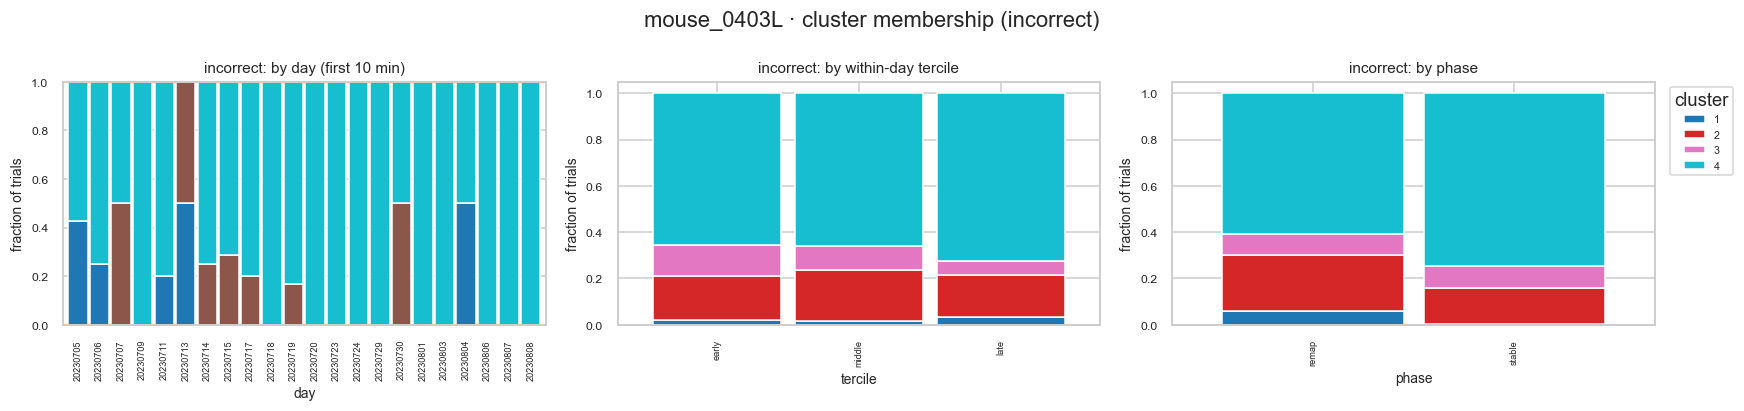

  incorrect cluster x day     : chi2=    179.8 dof=  99 p=1.26e-06
  incorrect cluster x tercile : chi2=      8.8 dof=   6 p=0.183
  incorrect cluster x phase   : chi2=     27.4 dof=   3 p=4.89e-06


In [21]:
def membership_panel(c, group_col, title, ax, order=None):
    ct = ca.cluster_composition(c["sub"], "cluster", group_col)
    if order is not None:
        ct = ct.reindex([o for o in order if o in ct.index])
    ct.plot(kind="bar", stacked=True, ax=ax, colormap="tab10", width=0.9, legend=False)
    ax.set(title=title, ylabel="fraction of trials", xlabel=group_col)
    ax.tick_params(axis="x", rotation=90, labelsize=6)
    return ct

for oc in ["correct", "incorrect"]:
    c = CLU[oc]
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    c_day = dict(c, sub=comparable_subset(c["sub"]))   # by-day panel: same 10-min restriction
    membership_panel(c_day, "day", f"{oc}: by day (first {FIRST_MIN_FOR_DAY_COMPARISON:.0f} min)", axes[0])
    membership_panel(c, "tercile", f"{oc}: by within-day tercile", axes[1], order=TERCILES)
    membership_panel(c, "phase", f"{oc}: by phase", axes[2])
    axes[2].legend(title="cluster", fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle(f"{CLUSTER_MOUSE} · cluster membership ({oc})")
    show(fig, f"S9_membership_{oc}")
    for g in ["day", "tercile", "phase"]:
        ct = pd.crosstab(c["sub"][g], c["sub"]["cluster"])
        if ct.shape[0] > 1 and ct.shape[1] > 1:
            chi2, p, dof, _ = chi2_contingency(ct)
            print(f"  {oc:9s} cluster x {g:8s}: chi2={chi2:9.1f} dof={dof:4d} p={p:.3g}")

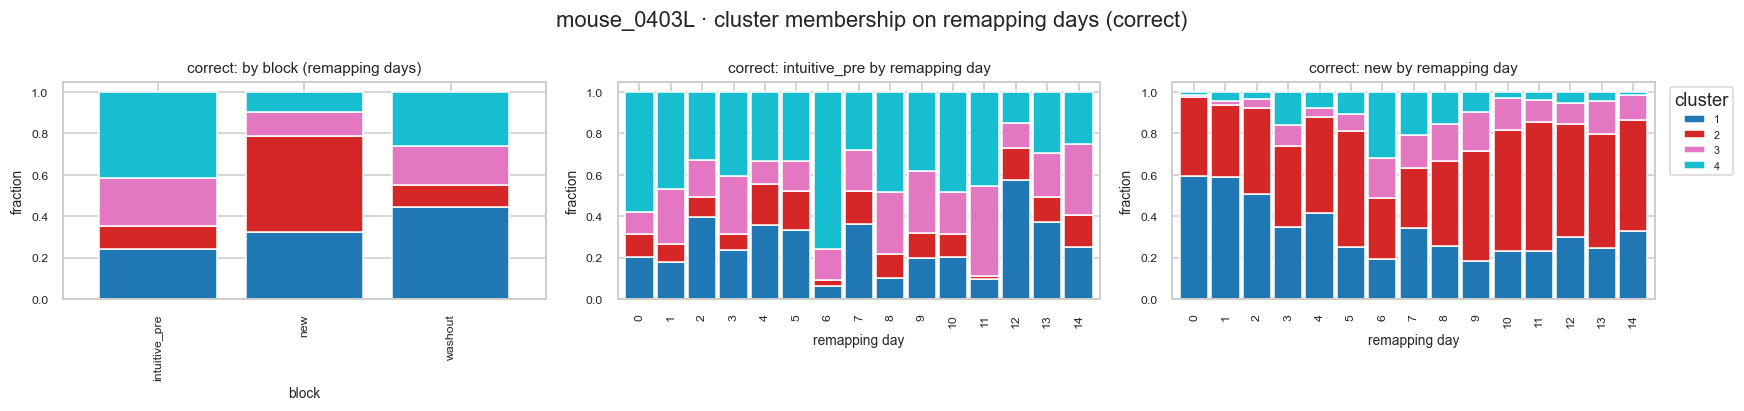

  correct   cluster x block: chi2=880.3 dof=6 p=6.72e-187


cluster,1,2,3,4
block,,,,
intuitive_pre,0.243,0.110,0.230,0.417
new,0.324,0.465,0.115,0.096
washout,0.445,0.106,0.188,0.261


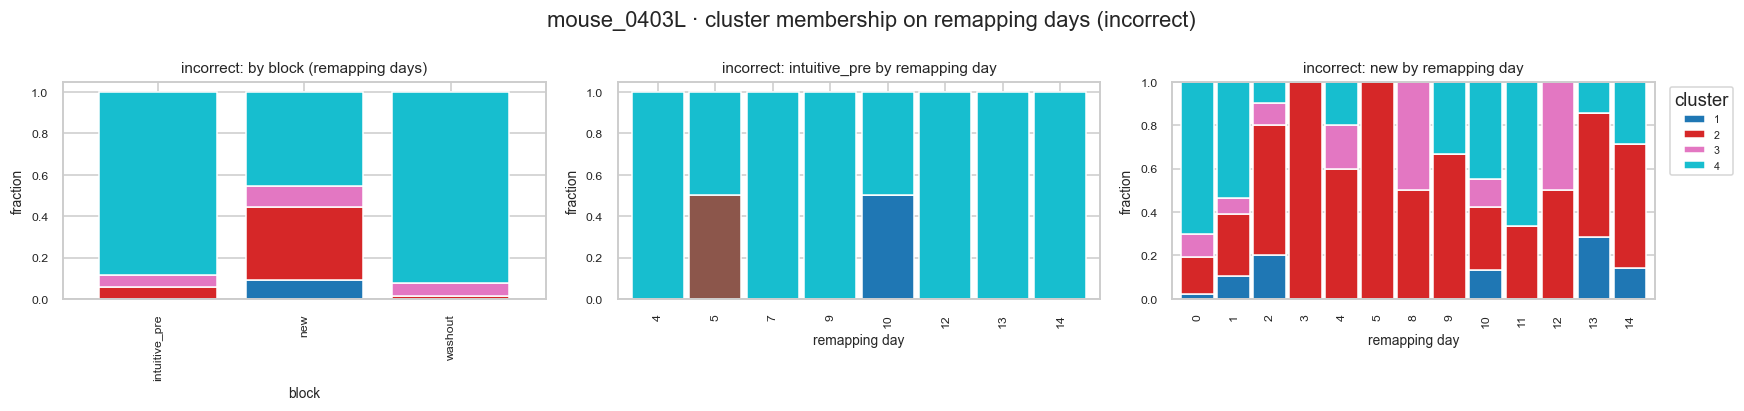

  incorrect cluster x block: chi2=52.6 dof=6 p=1.42e-09


cluster,1,2,3,4
block,,,,
intuitive_pre,0.000,0.059,0.059,0.882
new,0.091,0.352,0.103,0.455
washout,0.000,0.015,0.061,0.924


In [22]:
# remapping days only: membership by block (intuitive_pre / new / washout), and block x day
for oc in ["correct", "incorrect"]:
    c = CLU[oc]
    sub = c["sub"]
    rmx = sub[sub.phase == "remap"].copy()
    if rmx.empty: continue
    rmx["remap_day"] = rmx.day_from0 - rmx.day_from0.min()
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    ct = ca.cluster_composition(rmx, "cluster", "block").reindex(BLOCK_ORDER)
    ct.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10", width=0.8, legend=False)
    axes[0].set(title=f"{oc}: by block (remapping days)", ylabel="fraction")
    for ax, blk in zip(axes[1:], ["intuitive_pre", "new"]):
        b = rmx[rmx.block == blk]
        if b.empty: continue
        ca.cluster_composition(b, "cluster", "remap_day").plot(
            kind="bar", stacked=True, ax=ax, colormap="tab10", width=0.9, legend=False)
        ax.set(title=f"{oc}: {blk} by remapping day", ylabel="fraction", xlabel="remapping day")
    axes[-1].legend(title="cluster", fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle(f"{CLUSTER_MOUSE} · cluster membership on remapping days ({oc})")
    show(fig, f"S9_membership_remap_{oc}")
    ct = pd.crosstab(rmx["block"], rmx["cluster"])
    if ct.shape[0] > 1 and ct.shape[1] > 1:
        chi2, p, dof, _ = chi2_contingency(ct)
        print(f"  {oc:9s} cluster x block: chi2={chi2:.1f} dof={dof} p={p:.3g}")
        display(ca.cluster_composition(rmx, "cluster", "block").reindex(BLOCK_ORDER).round(3))

## 10 · t-SNE and UMAP views

Both embeddings are computed **from the same PCA scores** used for clustering, and are shown only as
2-D views for inspection — no analysis depends on them. Neighbourhood-embedding coordinates are not
metric: distances between well-separated blobs, and the blobs' shapes, are not interpretable.

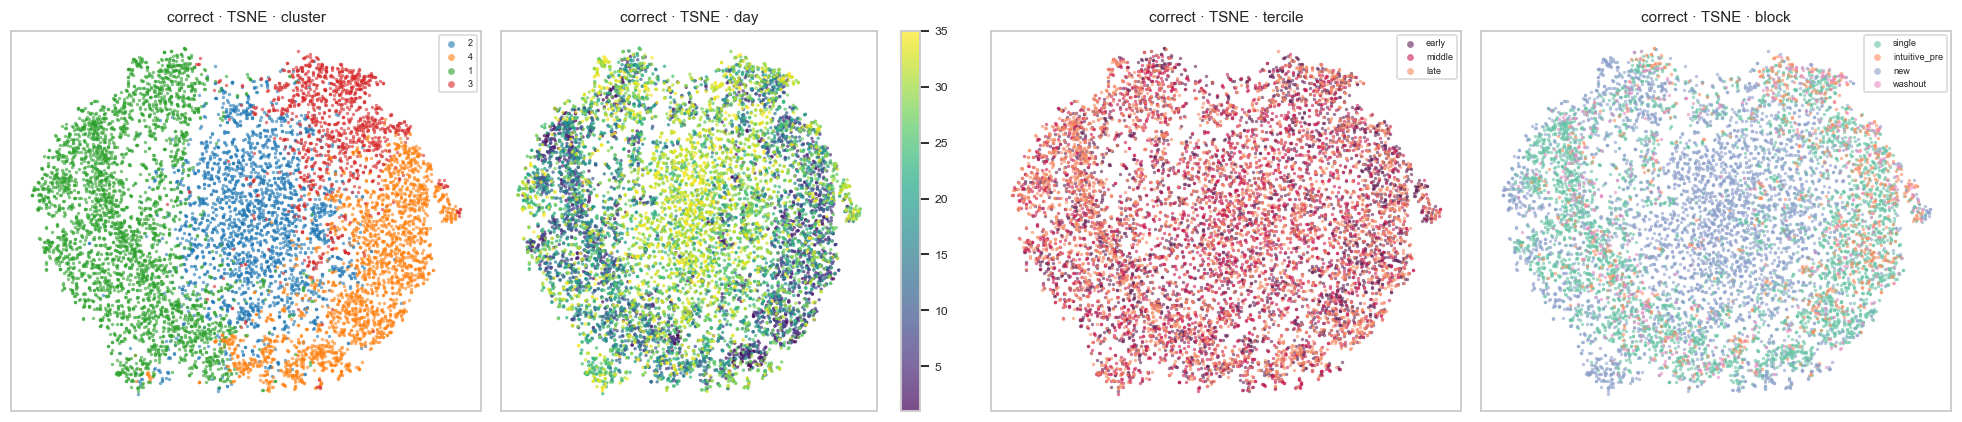

  [S10_umap_correct] saved (set FIG_LEVEL='full' to display)


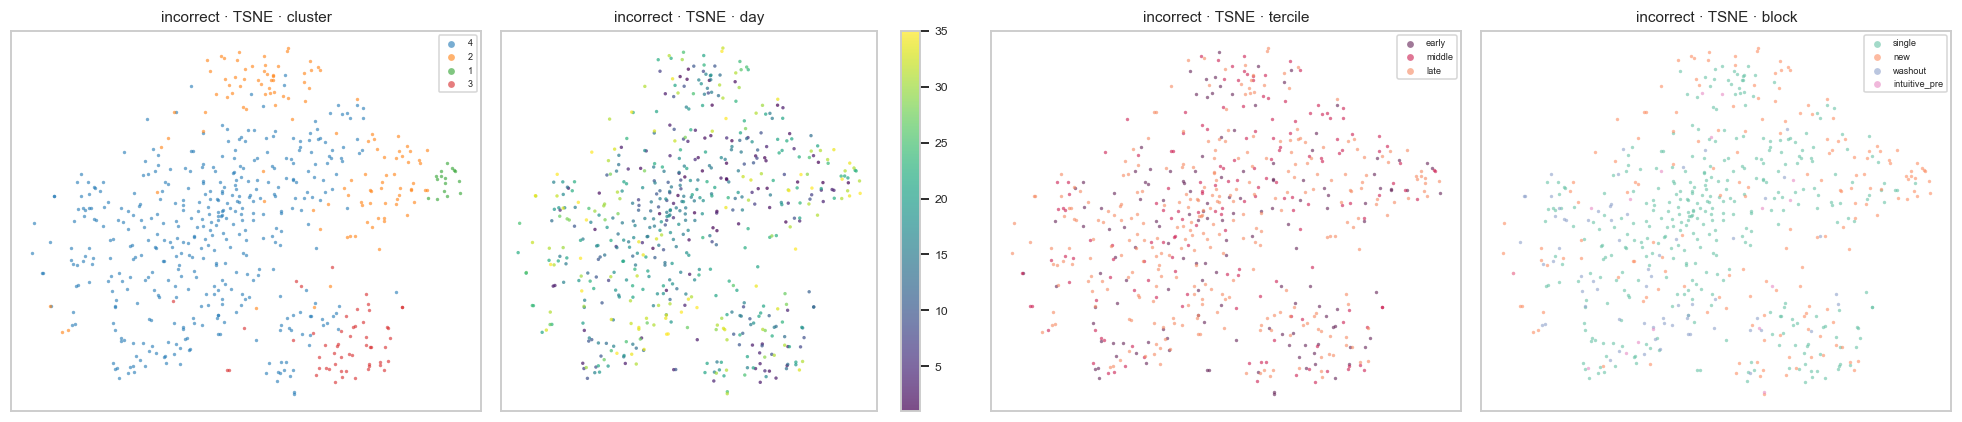

  [S10_umap_incorrect] saved (set FIG_LEVEL='full' to display)


In [23]:
emb_fp = OUT / f"embeddings_{TAG}_{NORMALIZE_MODE}_{CLUSTER_MOUSE}.npz"
if USE_CACHE and emb_fp.exists():
    _z = np.load(emb_fp)
    for oc in ["correct", "incorrect"]:
        CLU[oc]["tsne"] = _z[f"tsne_{oc}"]; CLU[oc]["umap"] = _z[f"umap_{oc}"]
else:
    for oc in ["correct", "incorrect"]:
        t0 = time.time()
        CLU[oc]["tsne"] = ca.embed_tsne(CLU[oc]["pca"].scores, perplexity=TSNE_PERPLEXITY, seed=SEED)
        CLU[oc]["umap"] = ca.embed_umap(CLU[oc]["pca"].scores, n_neighbors=UMAP_NEIGHBORS,
                                        min_dist=UMAP_MIN_DIST, seed=SEED)
        print(f"  {oc}: embeddings in {time.time()-t0:.0f}s")
    np.savez(emb_fp, **{f"{k}_{oc}": CLU[oc][k] for oc in ["correct", "incorrect"] for k in ["tsne", "umap"]})

def scatter_by(ax, E, values, title, cmap="tab10", discrete=True, s=5):
    v = pd.Series(values).reset_index(drop=True)
    if discrete:
        cats = list(pd.unique(v.dropna()))
        pal = sns.color_palette(cmap, max(len(cats), 2))
        for col, cat in zip(pal, cats):
            m = (v == cat).to_numpy()
            ax.scatter(E[m, 0], E[m, 1], s=s, color=col, alpha=0.6, linewidths=0, label=str(cat))
        if len(cats) <= 12: ax.legend(fontsize=6, markerscale=2)
    else:
        sc = ax.scatter(E[:, 0], E[:, 1], c=v.to_numpy(), s=s, cmap=cmap, alpha=0.7, linewidths=0)
        plt.colorbar(sc, ax=ax)
    ax.set(title=title, xticks=[], yticks=[])

for oc in ["correct", "incorrect"]:
    c = CLU[oc]; sub = c["sub"]
    for name in ["tsne", "umap"]:
        E = c[name]
        fig, axes = plt.subplots(1, 4, figsize=(18, 4))
        scatter_by(axes[0], E, sub.cluster, f"{oc} · {name.upper()} · cluster")
        scatter_by(axes[1], E, sub.day_from0, f"{oc} · {name.upper()} · day", cmap="viridis", discrete=False)
        scatter_by(axes[2], E, sub.tercile, f"{oc} · {name.upper()} · tercile", cmap="rocket")
        scatter_by(axes[3], E, sub.block, f"{oc} · {name.upper()} · block", cmap="Set2")
        show(fig, f"S10_{name}_{oc}", "summary" if name == "tsne" else "full")

## 11 · Correctness checks and caveats

Automated checks that the pipeline did what the methods section claims. These print PASS/FAIL rather
than being asserted, so a failure is visible without killing the notebook.

In [24]:
checks = []
def chk(name, ok, detail=""):
    checks.append(dict(check=name, result="PASS" if ok else "FAIL", detail=detail))

chk("matrix/metadata aligned", len(M_all) == len(trials_df), f"{len(M_all)} vs {len(trials_df)}")
chk("no NaN in window matrix", np.isfinite(M_all).all())
chk("window width matches spec", M_all.shape[1] == SPEC.n_cols, f"{M_all.shape[1]} == {SPEC.n_cols}")
chk("incorrect trials are the 20 s timeout",
    np.allclose(trials_df.loc[trials_df.outcome == 'incorrect', 'duration_sec'].median(), MISS_DUR_SEC, atol=0.1),
    f"median={trials_df.loc[trials_df.outcome=='incorrect','duration_sec'].median():.2f}s")
chk("correct trials shorter than the timeout",
    trials_df.loc[trials_df.outcome == 'correct', 'duration_sec'].median() < MISS_DUR_SEC,
    f"median={trials_df.loc[trials_df.outcome=='correct','duration_sec'].median():.2f}s")
chk("every remapping day has 3 blocks",
    set(trials_df[trials_df.phase == 'remap'].block.unique()) <= set(BLOCK_ORDER),
    str(sorted(trials_df[trials_df.phase == 'remap'].block.unique())))
chk("terciles are equal-count (within 1%)",
    trials_df.groupby(['mouse', 'day']).tercile.value_counts(normalize=True).between(0.30, 0.37).mean() > 0.9)
chk("clustering used the PCA scores, not the embeddings",
    all(CLU[o]['pca'].scores.shape[0] == len(CLU[o]['sub']) for o in CLU))
chk("PCA reaches the variance target",
    all(np.cumsum(CLU[o]['pca'].explained_ratio)[CLU[o]['pca'].n_kept - 1] >= PCA_VAR_TARGET for o in CLU))
# flank/trial overlap: does any window reach into the neighbouring trial?
gap_ok = []
for (mo, dy), g in trials_df.groupby(["mouse", "day"]):
    g = g.sort_values("start_frame")
    gaps = (g.start_frame.to_numpy()[1:] - g.end_frame.to_numpy()[:-1]) / SR
    if len(gaps): gap_ok.append(np.mean(gaps >= POST_SEC + PRE_SEC))
chk("windows do not overlap neighbouring trials",
    np.mean(gap_ok) > 0.95, f"{100*np.mean(gap_ok):.1f}% of gaps >= pre+post")
display(pd.DataFrame(checks))

print("\nCaveats to keep in mind when reading the figures above:")
print(" 1. Linear time-warping equates a fast and a slow trial of the same shape; real duration is")
print("    kept separately (duration_sec, path_length_raw_per_s).")
print(" 2. Incorrect trials all last exactly 20 s, so their warping is nearly the identity, while")
print("    correct trials (median ~3 s) are stretched -- never compare warped time axes between")
print("    outcomes as if they were the same real timescale.")
print(" 3. Washout is always the last block of the session, so washout-vs-other differences are")
print("    confounded with time-on-task and motivation (see the within-washout drift table).")
print(" 4. Cluster count k is a modelling choice from a silhouette heuristic, not a discovered truth.")
print(" 5. p-values are descriptive: many metrics are tested with no multiple-comparison correction,")
print("    and with thousands of trials even tiny differences reach significance.")
print(" 6. t-SNE / UMAP geometry is not metric and is used for inspection only.")

,check,result,detail
0,matrix/metadata aligned,PASS,16036 vs 16036
1,no NaN in window matrix,PASS,
2,window width matches spec,PASS,63 == 63
3,incorrect trials are the 20 s timeout,PASS,median=20.00s
4,correct trials shorter than the timeout,PASS,median=2.37s
5,every remapping day has 3 blocks,PASS,"['intuitive_pre', 'new', 'washout']"
6,terciles are equal-count (within 1%),PASS,
7,"clustering used the PCA scores, not the embeddings",PASS,
8,PCA reaches the variance target,PASS,
9,windows do not overlap neighbouring trials,PASS,100.0% of gaps >= pre+post



Caveats to keep in mind when reading the figures above:
 1. Linear time-warping equates a fast and a slow trial of the same shape; real duration is
    kept separately (duration_sec, path_length_raw_per_s).
 2. Incorrect trials all last exactly 20 s, so their warping is nearly the identity, while
    correct trials (median ~3 s) are stretched -- never compare warped time axes between
    outcomes as if they were the same real timescale.
 3. Washout is always the last block of the session, so washout-vs-other differences are
    confounded with time-on-task and motivation (see the within-washout drift table).
 4. Cluster count k is a modelling choice from a silhouette heuristic, not a discovered truth.
 5. p-values are descriptive: many metrics are tested with no multiple-comparison correction,
    and with thousands of trials even tiny differences reach significance.
 6. t-SNE / UMAP geometry is not metric and is used for inspection only.
